# IS453 Group Assignment — G1-7 — Medical Procedure Loan
## Credit scorecard: full pipeline in one notebook

This notebook uses the two course data files to develop a **proxy-based medical-procedure-loan credit scorecard** with training-derived IV/WoE bins, validation-based tuning and a held-out test evaluation. The historical data does not confirm the actual purpose of each cash loan.

| Part | What it does | Assignment component |
|---|---|---|
| 1 | Segment filtering and checkpoint counts | 2. Data selection |
| 2 | Bureau cleaning, applicant-level aggregation and left join | 2. Data preparation |
| 3 | Modelling table and stratified 70/15/15 split | 2. Data preparation |
| 4 | Fine classing, IV screening, automatic coarse classing | 3. Screening and grouping |
| 5 | Training-fit logistic regression and validation-based forward selection | 4. Logistic regression |
| 6 | Tuning, final scorecard and AUC/Gini/KS evaluation | 5. Model tuning |
| 7 | Validation-selected cutoff, hypothetical profit and rate scenarios | 6. Cutoff, interest rate and profitability |
| 8 | Three historical test applicants scored point by point | 7. Scorecard walkthrough |

**Input CSV files** (in the notebook's working directory):
* `IS453 Group Assignment - Application Data.csv`
* `IS453 Group Assignment - Bureau Data.csv`

**Main outputs:**
* Filtering and screening: `g7_segment_sensitivity.csv`, `g7_iv_fine_classing.csv`, `g7_missingness_screened.csv`
* Model selection: `g7_forward_selection_validation.csv`, `g7_tuning_validation.csv`, `g7_binning_comparison_validation.csv`, `g7_binning_details_validation.csv`
* Scorecard: `g7_scorecard_points.csv`, `g7_final_bins_and_points.csv`, `g7_final_model_performance.csv`, `g7_calibration_audit.csv`
* Figures: `g7_roc_ks_curves.png`, `g7_score_distribution.png`, `g7_profit_curve.png`
* Business scenarios: `g7_profit_sensitivity.csv`, `g7_pricing_scenario_validation.csv`
* Walkthrough and prediction contract: `g7_applicant_walkthrough_test.csv`, `g7_deployment_features.csv`

The outputs are scenario-based, and **financial quantities are in unspecified dataset monetary units, not verified SGD**.

## 0. Setup
Same packages as the Week 11 lab. After the two `pip install` lines finish, restart the kernel
and run the cell again, as the lab says. If you see an error about numpy "dtype size changed",
change the first line to `%pip install pandas==2.1.1 "numpy<2"` and restart the kernel again.

In [1]:
%pip install pandas==2.1.1
%pip install scorecardpy==0.1.9.7
# after the installs finish: restart the kernel, then run this cell again

import warnings
import os
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning,ignore::FutureWarning'
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=FutureWarning, module='scorecardpy')

import pandas as pd, numpy as np
warnings.filterwarnings('ignore', category=pd.errors.SettingWithCopyWarning)  # raised inside scorecardpy, harmless
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model, metrics
import scorecardpy as sc
import pprint

print('pandas', pd.__version__, '| scorecardpy', sc.__version__)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


pandas 2.1.1 | scorecardpy 0.1.9.7


## Part 1. Segment filtering

**Selected customer segment — assumed product proxy, not observed medical loan purpose:**

| # | Filter | Rationale and limitation |
|---|---|---|
| 1 | `NAME_CONTRACT_TYPE == 'Cash loans'` | A one-off cash advance with instalment repayments can approximate procedure financing; loan purpose is not observed. |
| 2 | `50,000 <= AMT_CREDIT <= 250,000` | A relatively smaller-ticket cash-loan segment in the **dataset's unspecified monetary units**; this is a modelling assumption, not a proven medical-bill price range. |
| 3 | `25 <= age <= 65` (`-DAYS_BIRTH / 365.25`) | An assumed product-eligibility age range, **not** evidence that people outside this range do not need medical financing. Excluding older applicants limits applicability. |
| 4 | `NAME_INCOME_TYPE` in Working, Commercial associate, State servant, Pensioner | Retains selected income categories as an assumed affordability/eligibility rule; actual repayment capacity must still be assessed. |
| 5 | `AMT_ANNUITY` observed and `AMT_INCOME_TOTAL > 0` | Requires available instalment and positive-income data for affordability-related features. |

`ORGANIZATION_TYPE == 'Medicine'` is **not** used: it indicates the applicant's employer industry, not the loan purpose. `TARGET` is used to report observed bad rates, not as a directly applied filtering condition. Segment choice must be defended on business grounds rather than optimised using observed bad rates.

In [2]:
app = pd.read_csv('IS453 Group Assignment - Application Data.csv', low_memory=False)
assert app['SK_ID_CURR'].is_unique, 'each row should be one application'
app['AGE_YEARS'] = -app['DAYS_BIRTH'] / 365.25

In [3]:
f1 = app['NAME_CONTRACT_TYPE'] == 'Cash loans'
f2 = app['AMT_CREDIT'].between(50000, 250000)
f3 = app['AGE_YEARS'].between(25, 65)
f4 = app['NAME_INCOME_TYPE'].isin(['Working', 'Commercial associate', 'State servant', 'Pensioner'])
f5 = app['AMT_ANNUITY'].notna() & (app['AMT_INCOME_TOTAL'] > 0)

steps = [('Original data', pd.Series(True, index=app.index)),
         ('1. Cash loans', f1),
         ('2. + loan amount 50k-250k', f1 & f2),
         ('3. + age 25-65', f1 & f2 & f3),
         ('4. + income type', f1 & f2 & f3 & f4),
         ('5. + annuity known, income > 0', f1 & f2 & f3 & f4 & f5)]

funnel = pd.DataFrame([dict(step=name, rows=int(m.sum()), bads=int(app.loc[m, 'TARGET'].sum()),
                            bad_rate=app.loc[m, 'TARGET'].mean()) for name, m in steps]).set_index('step')
funnel['share_of_original'] = funnel['rows'] / len(app)
funnel.style.format({'rows': '{:,}', 'bads': '{:,}', 'bad_rate': '{:.2%}', 'share_of_original': '{:.1%}'})

,rows,bads,bad_rate,share_of_original
step,,,,
Original data,"307,511","24,825",8.07%,100.0%
1. Cash loans,"278,232","23,221",8.35%,90.5%
2. + loan amount 50k-250k,"44,460","3,225",7.25%,14.5%
3. + age 25-65,"38,266","2,871",7.50%,12.4%
4. + income type,"38,265","2,871",7.50%,12.4%
"5. + annuity known, income > 0","38,263","2,871",7.50%,12.4%


In [4]:
seg = app[f1 & f2 & f3 & f4 & f5].copy()
base_rate, seg_rate = app['TARGET'].mean(), seg['TARGET'].mean()
print(f"Segment: {len(seg):,} rows, {int(seg['TARGET'].sum()):,} bads, bad rate {seg_rate:.2%}")
print(f"Original: {len(app):,} rows, bad rate {base_rate:.2%}  ->  segment is {seg_rate/base_rate:.2f}x the original bad rate")

Segment: 38,263 rows, 2,871 bads, bad rate 7.50%
Original: 307,511 rows, bad rate 8.07%  ->  segment is 0.93x the original bad rate


In [5]:
# NEW — segment sensitivity: show how each BUSINESS filter changes the population.
# Interpret bad-rate differences descriptively; do not select rules using TARGET after seeing these outcomes.
segment_scenarios = {
    'All applications': pd.Series(True, index=app.index),
    'Cash loans only (baseline)': f1,
    'Cash + 50k-250k': f1 & f2,
    'Cash + amount + income + completeness (no age cap)': f1 & f2 & f4 & f5,
    'Current five filters': f1 & f2 & f3 & f4 & f5,
}
segment_audit = pd.DataFrame([
    {'segment': name, 'rows': int(mask.sum()),
     'bads': int(app.loc[mask, 'TARGET'].sum()),
     'bad_rate': app.loc[mask, 'TARGET'].mean(),
     'retained_pct': mask.mean()}
    for name, mask in segment_scenarios.items()
]).set_index('segment')
assert segment_audit.loc['Current five filters', 'rows'] == len(seg)
print(segment_audit.round(4).to_string())
segment_audit.to_csv('g7_segment_sensitivity.csv')

                                                      rows   bads  bad_rate  retained_pct
segment                                                                                  
All applications                                    307511  24825    0.0807        1.0000
Cash loans only (baseline)                          278232  23221    0.0835        0.9048
Cash + 50k-250k                                      44460   3225    0.0725        0.1446
Cash + amount + income + completeness (no age cap)   44457   3225    0.0725        0.1446
Current five filters                                 38263   2871    0.0750        0.1244


**Observed bad rate after filtering.** The final 50k–250k segment contains **38,263 applicants** and **2,871 cases with `TARGET = 1`**, a **7.50% payment-difficulty rate**, compared with **8.07%** in the full application dataset. The segment therefore has a **lower**, not higher, observed bad rate.

This comparison describes the selected historical sample; it does not establish that these loans financed medical procedures. The segment-sensitivity output shows how each business filter changes the population. In particular, omitting the age rule while keeping the other conditions gives 44,457 applicants and a 7.25% observed bad rate, versus 38,263 and 7.50% with the age rule. The age restriction must therefore be justified as a product assumption, not as an empirically demonstrated risk-reduction measure.

In [6]:
cash = app[f1]
credit_band = pd.cut(cash['AMT_CREDIT'], [0, 50000, 250000, 500000, 750000, 1000000, np.inf])
cash.groupby(credit_band, observed=True)['TARGET'].agg(rows='size', bad_rate='mean').style.format({'rows': '{:,}', 'bad_rate': '{:.2%}'})

,rows,bad_rate
AMT_CREDIT,,
"(0.0, 50000.0]",561,4.10%
"(50000.0, 250000.0]","44,460",7.25%
"(250000.0, 500000.0]","78,953",9.93%
"(500000.0, 750000.0]","62,891",9.70%
"(750000.0, 1000000.0]","42,089",7.38%
"(1000000.0, inf]","49,278",5.94%


In [7]:
age_band = pd.cut(seg['AGE_YEARS'], [25, 30, 35, 45, 55, 65.01], right=False)
seg.groupby(age_band, observed=True)['TARGET'].agg(rows='size', bad_rate='mean').style.format({'rows': '{:,}', 'bad_rate': '{:.2%}'})

,rows,bad_rate
AGE_YEARS,,
"[25.0, 30.0)","5,776",10.09%
"[30.0, 35.0)","5,838",10.09%
"[35.0, 45.0)","10,193",7.94%
"[45.0, 55.0)","7,936",6.36%
"[55.0, 65.01)","8,520",4.52%


**Does this proxy resemble a possible procedure-financing product?** Relative to all cash loans, the selected segment has **smaller loan amounts** (median 177,903 versus 540,000 dataset units) and a **lower loan-to-annuity ratio** (median 12.6 versus 20.7). The ratio is **not observed contractual tenure**. These characteristics are consistent with the *design assumption* of relatively smaller, one-off financing, but the dataset does not identify actual medical spending or prove the selected loans were used for procedures.

In [8]:
compare = pd.DataFrame({
    'All cash loans': [cash['AMT_CREDIT'].median(),
                       (cash['AMT_CREDIT'] / cash['AMT_ANNUITY']).median(),
                       cash['AMT_INCOME_TOTAL'].median()],
    'Selected segment': [seg['AMT_CREDIT'].median(),
                         (seg['AMT_CREDIT'] / seg['AMT_ANNUITY']).median(),
                         seg['AMT_INCOME_TOTAL'].median()]},
    index=['Median loan amount (dataset units)',
           'Median credit/annuity ratio (NOT contractual months)',
           'Median annual income (dataset units)'])
print(compare.round(1).to_string())

                                                      All cash loans  Selected segment
Median loan amount (dataset units)                          540000.0          177903.0
Median credit/annuity ratio (NOT contractual months)            20.7              12.6
Median annual income (dataset units)                        153000.0          112500.0


## Part 2. Bureau data: why it cannot be joined directly
The application data has **one row per applicant**. The bureau data has **one row per credit the applicant holds at
other lenders**. A direct left join (Option 1 in the data-merging module) would repeat each applicant once per credit and
create false extra "bad" rows. Spreading credits into columns (Option 2) would give many mostly empty columns. So we use
**Option 3**: summarise each applicant's credits into a set of features, then join one row per applicant.

In [9]:
bureau = pd.read_csv('IS453 Group Assignment - Bureau Data.csv', low_memory=False)
per_applicant = bureau.groupby('SK_ID_CURR').size()
print(f'bureau rows: {len(bureau):,} | applicants: {bureau["SK_ID_CURR"].nunique():,} | '
      f'credits per applicant: median {per_applicant.median():.0f}, max {per_applicant.max()}')

bureau rows: 1,716,428 | applicants: 305,811 | credits per applicant: median 4, max 116


### 2.1 Data quality checks
Run before summarising, because a bad value becomes invisible once it is added into a total.

In [10]:
print('-- issues to fix --')
print(f'negative AMT_CREDIT_SUM_DEBT  : {(bureau.AMT_CREDIT_SUM_DEBT < 0).sum():,}  (a debt cannot be negative)')
print(f'negative AMT_CREDIT_SUM_LIMIT : {(bureau.AMT_CREDIT_SUM_LIMIT < 0).sum():,}  (a limit cannot be negative)')
print(f'DAYS_CREDIT_UPDATE > 0        : {(bureau.DAYS_CREDIT_UPDATE > 0).sum():,}  (updated after the application = future information)')
print(f'DAYS_CREDIT > 0               : {(bureau.DAYS_CREDIT > 0).sum():,}')
print()
print('-- not an issue --')
print(f'DAYS_CREDIT_ENDDATE > 0       : {(bureau.DAYS_CREDIT_ENDDATE > 0).sum():,}  (the credit is still running)')
print()
print(bureau['CREDIT_CURRENCY'].value_counts().to_string())

-- issues to fix --
negative AMT_CREDIT_SUM_DEBT  : 8,418  (a debt cannot be negative)
negative AMT_CREDIT_SUM_LIMIT : 351  (a limit cannot be negative)
DAYS_CREDIT_UPDATE > 0        : 17  (updated after the application = future information)
DAYS_CREDIT > 0               : 0

-- not an issue --
DAYS_CREDIT_ENDDATE > 0       : 602,603  (the credit is still running)

CREDIT_CURRENCY
currency 1    1715020
currency 2       1224
currency 3        174
currency 4         10


### 2.2 Clean
* Remove bureau records whose credit-update date is after the application (`DAYS_CREDIT_UPDATE > 0`), as that information would not have been available at the lending decision.
* Clip negative reported debt and credit-limit values to zero, as specified in the cleaning rule.
* `CREDIT_CURRENCY` is anonymised and exchange rates are unavailable. Foreign-currency bureau credits are **flagged but not converted**; amounts are still aggregated. Their number is small in the selected segment, but the impact of incomparable monetary units is **not independently quantified** and remains a limitation.

In [11]:
b = bureau[bureau['DAYS_CREDIT_UPDATE'] <= 0].copy()
b['AMT_CREDIT_SUM_DEBT']  = b['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
b['AMT_CREDIT_SUM_LIMIT'] = b['AMT_CREDIT_SUM_LIMIT'].clip(lower=0)
b['IS_FOREIGN_CCY'] = (b['CREDIT_CURRENCY'] != 'currency 1').astype(int)
print(f'{len(bureau):,} -> {len(b):,} rows ({len(bureau) - len(b)} dropped as post-application updates)')

1,716,428 -> 1,716,411 rows (17 dropped as post-application updates)


### 2.3 Yes/no flags for each credit
Each flag is 1 or 0 for each credit, so adding them up per applicant gives a count.
`DAYS_CREDIT` is negative (days before the application), so "opened in the last 12 months" means `DAYS_CREDIT >= -365`.

In [12]:
b['F_ACTIVE']       = (b['CREDIT_ACTIVE'] == 'Active').astype(int)
b['F_CLOSED']       = (b['CREDIT_ACTIVE'] == 'Closed').astype(int)
b['F_BAD_DEBT']     = b['CREDIT_ACTIVE'].isin(['Bad debt', 'Sold']).astype(int)
b['F_OVERDUE_NOW']  = (b['CREDIT_DAY_OVERDUE'] > 0).astype(int)
b['F_EVER_OVERDUE'] = ((b['CREDIT_DAY_OVERDUE'] > 0) | (b['AMT_CREDIT_MAX_OVERDUE'].fillna(0) > 0)).astype(int)
b['F_PROLONGED']    = (b['CNT_CREDIT_PROLONG'] > 0).astype(int)
b['F_CONSUMER']     = (b['CREDIT_TYPE'] == 'Consumer credit').astype(int)
b['F_CARD']         = (b['CREDIT_TYPE'] == 'Credit card').astype(int)
b['F_MICROLOAN']    = (b['CREDIT_TYPE'] == 'Microloan').astype(int)
b['F_SECURED']      = b['CREDIT_TYPE'].isin(['Car loan', 'Mortgage', 'Real estate loan']).astype(int)
b['F_OPENED_12M']   = (b['DAYS_CREDIT'] >= -365).astype(int)
b['F_OPENED_24M']   = (b['DAYS_CREDIT'] >= -730).astype(int)
# amounts on active credits only, so paid-off credits do not count as current debt
b['ACT_DEBT']   = b['AMT_CREDIT_SUM_DEBT'].where(b['F_ACTIVE'] == 1)
b['ACT_CREDIT'] = b['AMT_CREDIT_SUM'].where(b['F_ACTIVE'] == 1)

### 2.4 Summarise to one row per applicant
Only the segment's applicants are summarised. `groupby('SK_ID_CURR').agg(...)` works like a pivot table: one row per
applicant, with each new column built as `NEW_NAME = ('column', 'how')`.

| Family | Features |
|---|---|
| Account counts | total, active, closed, sold / bad debt |
| Delinquency | overdue now, ever overdue, prolonged, worst days and amount overdue |
| Exposure | total credit and debt, active credit and debt, largest and average credit |
| Credit mix | consumer, card, microloan, secured, number of credit types, foreign currency |
| History and recency | first and latest credit, opened in the last 12 and 24 months |

In [13]:
b_seg = b[b['SK_ID_CURR'].isin(seg['SK_ID_CURR'])]

agg = b_seg.groupby('SK_ID_CURR').agg(
    BUR_N_CREDITS        = ('SK_ID_BUREAU', 'count'),
    BUR_N_ACTIVE         = ('F_ACTIVE', 'sum'),
    BUR_N_CLOSED         = ('F_CLOSED', 'sum'),
    BUR_N_BAD_DEBT       = ('F_BAD_DEBT', 'sum'),
    BUR_N_OVERDUE_NOW    = ('F_OVERDUE_NOW', 'sum'),
    BUR_N_EVER_OVERDUE   = ('F_EVER_OVERDUE', 'sum'),
    BUR_N_PROLONGED      = ('F_PROLONGED', 'sum'),
    BUR_MAX_DAYS_OVERDUE = ('CREDIT_DAY_OVERDUE', 'max'),
    BUR_MAX_AMT_OVERDUE  = ('AMT_CREDIT_MAX_OVERDUE', 'max'),
    BUR_SUM_OVERDUE_NOW  = ('AMT_CREDIT_SUM_OVERDUE', 'sum'),
    BUR_SUM_CREDIT       = ('AMT_CREDIT_SUM', 'sum'),
    BUR_SUM_DEBT         = ('AMT_CREDIT_SUM_DEBT', 'sum'),
    BUR_MAX_CREDIT       = ('AMT_CREDIT_SUM', 'max'),
    BUR_MEAN_CREDIT      = ('AMT_CREDIT_SUM', 'mean'),
    BUR_SUM_ACT_DEBT     = ('ACT_DEBT', 'sum'),
    BUR_SUM_ACT_CREDIT   = ('ACT_CREDIT', 'sum'),
    BUR_N_CONSUMER       = ('F_CONSUMER', 'sum'),
    BUR_N_CARD           = ('F_CARD', 'sum'),
    BUR_N_MICROLOAN      = ('F_MICROLOAN', 'sum'),
    BUR_N_SECURED        = ('F_SECURED', 'sum'),
    BUR_N_CREDIT_TYPES   = ('CREDIT_TYPE', 'nunique'),
    BUR_N_FOREIGN_CCY    = ('IS_FOREIGN_CCY', 'sum'),
    BUR_DAYS_FIRST       = ('DAYS_CREDIT', 'min'),
    BUR_DAYS_LAST        = ('DAYS_CREDIT', 'max'),
    BUR_N_OPENED_12M     = ('F_OPENED_12M', 'sum'),
    BUR_N_OPENED_24M     = ('F_OPENED_24M', 'sum'),
).reset_index()

# ratios: a 0 denominator gives a blank (NaN), never 0, so the binning gives it a Missing bin
agg['BUR_UTILISATION']       = agg['BUR_SUM_ACT_DEBT'] / agg['BUR_SUM_ACT_CREDIT'].replace(0, np.nan)
agg['BUR_DEBT_TO_CREDIT']    = agg['BUR_SUM_DEBT'] / agg['BUR_SUM_CREDIT'].replace(0, np.nan)
agg['BUR_SHARE_ACTIVE']      = agg['BUR_N_ACTIVE'] / agg['BUR_N_CREDITS']
agg['BUR_SHARE_OVERDUE']     = agg['BUR_N_EVER_OVERDUE'] / agg['BUR_N_CREDITS']
agg['BUR_HISTORY_YEARS']     = -agg['BUR_DAYS_FIRST'] / 365.25
agg['BUR_MONTHS_SINCE_LAST'] = -agg['BUR_DAYS_LAST'] / 30.44
agg['BUR_EVER_OVERDUE_FLAG'] = (agg['BUR_N_EVER_OVERDUE'] > 0).astype(int)

assert agg['SK_ID_CURR'].is_unique, 'must be one row per applicant'
print(f'{len(b_seg):,} bureau rows for the segment -> {len(agg):,} applicants x {agg.shape[1] - 1} features')
agg.head()

177,874 bureau rows for the segment -> 32,157 applicants x 33 features


,SK_ID_CURR,BUR_N_CREDITS,BUR_N_ACTIVE,BUR_N_CLOSED,BUR_N_BAD_DEBT,BUR_N_OVERDUE_NOW,BUR_N_EVER_OVERDUE,BUR_N_PROLONGED,BUR_MAX_DAYS_OVERDUE,BUR_MAX_AMT_OVERDUE,...,BUR_DAYS_LAST,BUR_N_OPENED_12M,BUR_N_OPENED_24M,BUR_UTILISATION,BUR_DEBT_TO_CREDIT,BUR_SHARE_ACTIVE,BUR_SHARE_OVERDUE,BUR_HISTORY_YEARS,BUR_MONTHS_SINCE_LAST,BUR_EVER_OVERDUE_FLAG
0,100015,4,0,4,0,0,0,0,0,NaN,...,-319,1,1,NaN,0.000000,0.000000,0.0,3.857632,10.479632,0
1,100016,7,4,3,0,0,0,0,0,0.0,...,-128,4,5,0.189230,0.134161,0.571429,0.0,4.473648,4.204993,0
2,100029,4,1,3,0,0,0,0,0,NaN,...,-110,1,1,0.985887,0.495728,0.250000,0.0,7.682409,3.613666,0
3,100030,6,2,4,0,0,0,0,0,0.0,...,-418,0,2,0.815976,0.701928,0.333333,0.0,4.235455,13.731932,0
4,100037,8,1,7,0,0,0,0,0,0.0,...,-1247,0,0,0.000000,0.000000,0.125000,0.0,7.559206,40.965834,0



### 2.5 Left join and missing values

A **left join** merges the applicant-level bureau summaries into the application dataset using `SK_ID_CURR`, while retaining every applicant in the selected segment.

This is important because some applicants have no matching records in the available bureau dataset. An inner join would remove these applicants, potentially introducing selection bias and reducing the representativeness of the modelling population.

In our selected segment:

- **32,157 applicants** have matching bureau records.
- **6,106 applicants (approximately 16.0%)** have no matching bureau records.
- Applicants without bureau records have an observed bad rate of **9.96%**, compared with **7.04%** among those with bureau records.

These figures describe a historical association. They do not establish that having no bureau history causes repayment difficulties.

#### Handling missing bureau features

For applicants without matching bureau records, missing values are handled according to the meaning of each feature:

| Feature type | Treatment | Explanation |
|---|---|---|
| Account counts (`BUR_N_...`) | Fill with **0** | No credit accounts were observed for the applicant in the available bureau extract. |
| Aggregated amounts (`BUR_SUM_...`) | Fill with **0** | No amounts were recorded in the matching bureau data. This does not prove the applicant has no financial obligations outside the available records. |
| Bureau event flags | Fill with **0** | The relevant event was not observed in the available bureau records. |
| Ratios, averages, maximums and dates | **Retain as missing (`NaN`)** | These measures may be undefined when the required credit records or denominators are unavailable. |

For example, `BUR_UTILISATION` measures active bureau debt relative to active bureau credit. If no usable active-credit denominator exists, the ratio is undefined.

Assigning utilisation a value of zero would imply that the applicant has a measured utilisation of 0%, which is not necessarily true.

Instead, the missing value is retained and can be represented by a separate missing-value bin during Weight of Evidence (WoE) transformation.

**Interpretation:** Missing bureau information means the relevant credit history was not observed in the available dataset. It should not automatically be interpreted as proof that the applicant has no existing debt, no previous overdue payments or no credit risk.

This approach preserves the full modelling population while allowing the scorecard to distinguish between observed zero values and unavailable information.


In [14]:
zero_fill = [c for c in agg.columns if c.startswith(('BUR_N_', 'BUR_SUM_'))] + ['BUR_EVER_OVERDUE_FLAG']
keep_blank = [c for c in agg.columns if c not in zero_fill + ['SK_ID_CURR']]

model_df = seg.merge(agg, on='SK_ID_CURR', how='left', validate='one_to_one')
model_df['HAS_BUREAU'] = model_df['BUR_N_CREDITS'].notna().astype(int)
model_df[zero_fill] = model_df[zero_fill].fillna(0)

# checks: same applicants, nobody duplicated, bads unchanged
assert len(model_df) == len(seg), 'row count changed during the merge'
assert model_df['SK_ID_CURR'].is_unique, 'an applicant appears twice'
assert model_df['TARGET'].sum() == seg['TARGET'].sum(), 'number of bads changed'
print(f'merged: {model_df.shape[0]:,} rows x {model_df.shape[1]} columns - all checks passed')
print(f'filled with 0 ({len(zero_fill)}): {", ".join(zero_fill)}')
print(f'left blank ({len(keep_blank)}): {", ".join(keep_blank)}')

merged: 38,263 rows x 155 columns - all checks passed
filled with 0 (21): BUR_N_CREDITS, BUR_N_ACTIVE, BUR_N_CLOSED, BUR_N_BAD_DEBT, BUR_N_OVERDUE_NOW, BUR_N_EVER_OVERDUE, BUR_N_PROLONGED, BUR_SUM_OVERDUE_NOW, BUR_SUM_CREDIT, BUR_SUM_DEBT, BUR_SUM_ACT_DEBT, BUR_SUM_ACT_CREDIT, BUR_N_CONSUMER, BUR_N_CARD, BUR_N_MICROLOAN, BUR_N_SECURED, BUR_N_CREDIT_TYPES, BUR_N_FOREIGN_CCY, BUR_N_OPENED_12M, BUR_N_OPENED_24M, BUR_EVER_OVERDUE_FLAG
left blank (12): BUR_MAX_DAYS_OVERDUE, BUR_MAX_AMT_OVERDUE, BUR_MAX_CREDIT, BUR_MEAN_CREDIT, BUR_DAYS_FIRST, BUR_DAYS_LAST, BUR_UTILISATION, BUR_DEBT_TO_CREDIT, BUR_SHARE_ACTIVE, BUR_SHARE_OVERDUE, BUR_HISTORY_YEARS, BUR_MONTHS_SINCE_LAST


In [15]:
# NEW — merge validation and data-quality audit
assert len(model_df) == len(seg)
assert model_df['SK_ID_CURR'].is_unique
assert model_df['TARGET'].isin([0, 1]).all()
assert int(model_df['TARGET'].sum()) == int(seg['TARGET'].sum())
assert (model_df['HAS_BUREAU'] == 0).sum() + (model_df['HAS_BUREAU'] == 1).sum() == len(seg)
assert model_df.loc[model_df['HAS_BUREAU'] == 0, 'BUR_N_CREDITS'].eq(0).all()
print('MERGE AUDIT: all applicant-grain, label, and missing-history checks passed')
print('Foreign-currency bureau credits (check exposure comparability):',
      int((b_seg['CREDIT_CURRENCY'] != 'currency 1').sum()))


MERGE AUDIT: all applicant-grain, label, and missing-history checks passed
Foreign-currency bureau credits (check exposure comparability): 76


### 2.6 Applicants with no bureau record (thin files)

In [16]:
thin = model_df.groupby('HAS_BUREAU')['TARGET'].agg(rows='size', bads='sum', bad_rate='mean')
thin['share'] = thin['rows'] / len(model_df)
thin.index = thin.index.map({0: 'No bureau record', 1: 'Has bureau record'})
thin.style.format({'rows': '{:,}', 'bads': '{:,}', 'bad_rate': '{:.2%}', 'share': '{:.1%}'})

,rows,bads,bad_rate,share
HAS_BUREAU,,,,
No bureau record,"6,106",608,9.96%,16.0%
Has bureau record,"32,157","2,263",7.04%,84.0%


### 2.7 Checkpoint summary

In [17]:
print('=' * 70)
print('G1-7 Medical procedure loan - segment and merge summary')
print('=' * 70)
print('filters: cash loans, loan amount 50k-250k, age 25-65, income type, annuity known and income > 0')
print(f'segment: {len(seg):,} rows ({len(seg)/len(app):.1%} of the original {len(app):,})')
print(f'bad rate: {seg_rate:.2%} vs {base_rate:.2%} in the original data')
print(f'bureau: {len(bureau):,} credit rows -> {len(agg):,} applicants with a record, {agg.shape[1]-1} features each')
print(f'merge: left join on SK_ID_CURR, {model_df.shape[0]:,} rows x {model_df.shape[1]} columns, one row per applicant')
print(f"thin files: {(model_df.HAS_BUREAU == 0).sum():,} ({(model_df.HAS_BUREAU == 0).mean():.1%}), "
      f"bad rate {model_df.loc[model_df.HAS_BUREAU == 0, 'TARGET'].mean():.2%} "
      f"vs {model_df.loc[model_df.HAS_BUREAU == 1, 'TARGET'].mean():.2%} with a record")

G1-7 Medical procedure loan - segment and merge summary
filters: cash loans, loan amount 50k-250k, age 25-65, income type, annuity known and income > 0
segment: 38,263 rows (12.4% of the original 307,511)
bad rate: 7.50% vs 8.07% in the original data
bureau: 1,716,428 credit rows -> 32,157 applicants with a record, 33 features each
merge: left join on SK_ID_CURR, 38,263 rows x 155 columns, one row per applicant
thin files: 6,106 (16.0%), bad rate 9.96% vs 7.04% with a record



## Part 3. Modelling table and train/validation/test split

### 3.1 Build the modelling table

The modelling table begins with the applicant-level dataset obtained after merging application and aggregated bureau information in Part 2.

Additional variables are engineered to capture financial exposure, repayment structure, employment history and historical credit behaviour.

These features follow the ratio-based feature engineering approach introduced in the Week 9 lab.

#### Engineered financial and credit-risk features

| Feature | Calculation | Interpretation |
|---|---|---|
| `CREDIT_TO_INCOME` | `AMT_CREDIT / AMT_INCOME_TOTAL` | Requested loan amount relative to the applicant's reported income. A financing-size and affordability-related proxy. |
| `ANNUITY_TO_INCOME` | `AMT_ANNUITY / AMT_INCOME_TOTAL` | Reported periodic loan repayment relative to reported income. An affordability-related proxy, not a verified disposable-income measure. |
| `CREDIT_TO_GOODS` | `AMT_CREDIT / AMT_GOODS_PRICE` | Loan amount relative to the recorded goods price. The goods price is **not a confirmed medical procedure cost or hospital bill**. |
| `TERM_MONTHS` | `AMT_CREDIT / AMT_ANNUITY` | Loan-to-annuity ratio, retained under its historical code name. It represents principal relative to periodic repayment, **not verified contractual loan tenure**. |
| `DEBT_TO_INCOME` | `(BUR_SUM_ACT_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL` | Existing active bureau debt plus the requested loan, relative to the applicant's reported income. |
| `INCOME_PER_PERSON` | `AMT_INCOME_TOTAL / CNT_FAM_MEMBERS` | Applicant's reported income divided by the recorded number of family members. This is **not total household income**, because the incomes of other family members are not included. |
| `BUR_ANY_MICROLOAN` | `1` if `BUR_N_MICROLOAN > 0`, otherwise `0` | Indicates whether at least one microloan was observed in the applicant's bureau history. |
| `BUR_ANY_OVERDUE_NOW` | `1` if `BUR_N_OVERDUE_NOW > 0`, otherwise `0` | Indicates whether at least one bureau account was recorded as currently overdue. |
| `BUR_ANY_BAD_DEBT` | `1` if `BUR_N_BAD_DEBT > 0`, otherwise `0` | Indicates whether at least one bureau record was classified as bad debt. |
| `ORGANIZATION_TYPE` | Grouping of existing employer-type labels | Consolidates employer categories into broader groups for modelling. It describes the applicant's employment organisation, **not the purpose of the loan**. |

#### Interpretation of the engineered ratios

These ratios capture different aspects of the applicant's financial situation:

- `CREDIT_TO_INCOME` compares the requested financing amount with reported income.
- `ANNUITY_TO_INCOME` compares scheduled repayment with reported income.
- `TERM_MONTHS` compares principal with periodic repayment, providing information about the loan's repayment structure.
- `DEBT_TO_INCOME` incorporates existing active bureau debt as well as the requested loan.
- `INCOME_PER_PERSON` adjusts the applicant's reported income for the number of recorded family members, but does not measure actual household disposable income.

The ratios are **predictive features rather than verified affordability assessments**. They do not independently establish the applicant's living expenses, disposable income or ability to repay.

In particular, `TERM_MONTHS` should not be used as the actual loan duration in the profitability model. Contractual tenure is not directly confirmed by the available data.

#### Time-based variables and anomalous values

Relevant day-count variables are converted into years to improve interpretability.

For employment history, `DAYS_EMPLOYED = 365243` is treated as a special placeholder rather than a valid employment duration.

The notebook therefore:

1. Creates `EMP_ANOMALY` to indicate whether the placeholder is present.
2. Replaces the placeholder with a missing value when calculating `YEARS_EMPLOYED`.
3. Preserves the missing employment-history information for subsequent processing and WoE binning.

Gender, identifier fields and constant or unsuitable predictors are excluded from model fitting where specified in the preprocessing code.

These engineered features are candidates for subsequent screening; they are **not automatically included in the final scorecard**. The final predictors are determined through correlation screening, IV/WoE analysis and validation-based forward selection.


In [18]:
# UPDATED — build one applicant-level modelling table, then split before supervised screening.
flat_cols = ['SK_ID_CURR', 'TARGET'] + [c for c in agg.columns if c != 'SK_ID_CURR'] + ['HAS_BUREAU']
app_cols = [c for c in app.columns if c not in ('SK_ID_CURR', 'TARGET', 'AGE_YEARS')]
df = model_df[flat_cols + app_cols].copy()
assert len(df) == len(seg) and df['SK_ID_CURR'].is_unique

df['AGE_YEARS']          = -df['DAYS_BIRTH'] / 365.25
df['EMP_ANOMALY']        = (df['DAYS_EMPLOYED'] == 365243).astype(int)
df['YEARS_EMPLOYED']     = -df['DAYS_EMPLOYED'].where(df['DAYS_EMPLOYED'] != 365243) / 365.25
df['YEARS_REGISTRATION'] = -df['DAYS_REGISTRATION'] / 365.25
df['YEARS_ID_PUBLISH']   = -df['DAYS_ID_PUBLISH'] / 365.25
df['YEARS_PHONE_CHANGE'] = -df['DAYS_LAST_PHONE_CHANGE'] / 365.25
df = df.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION',
                      'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE'])

df['CREDIT_TO_INCOME']  = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
df['ANNUITY_TO_INCOME'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
df['CREDIT_TO_GOODS']   = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']
# Keep the existing feature name to minimise downstream code changes; do NOT interpret as contractual tenure.
df['TERM_MONTHS']       = df['AMT_CREDIT'] / df['AMT_ANNUITY']
df['DEBT_TO_INCOME']    = (df['BUR_SUM_ACT_DEBT'] + df['AMT_CREDIT']) / df['AMT_INCOME_TOTAL']
df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']
df['BUR_ANY_MICROLOAN']   = (df['BUR_N_MICROLOAN'] > 0).astype(int)
df['BUR_ANY_OVERDUE_NOW'] = (df['BUR_N_OVERDUE_NOW'] > 0).astype(int)
df['BUR_ANY_BAD_DEBT']    = (df['BUR_N_BAD_DEBT'] > 0).astype(int)
df['ORGANIZATION_TYPE'] = df['ORGANIZATION_TYPE'].astype(str).str.replace(r':? [Tt]ype \d+$', '', regex=True)

df = df.drop(columns=['CODE_GENDER', 'BUR_DAYS_FIRST', 'BUR_DAYS_LAST'])
const = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
df = df.drop(columns=const)
# Keep ID, loan amount and the ratio for reporting / verification even if dropped as predictors.
loan_info = df[['SK_ID_CURR', 'AMT_CREDIT', 'TERM_MONTHS']].copy()
print('Non-finite numeric values will be mapped to missing before binning:',
      int(np.isinf(df.select_dtypes('number').to_numpy()).sum()))
print('Constant columns dropped:', const)
print('Modelling table before split:', df.shape)

Non-finite numeric values will be mapped to missing before binning: 0
Constant columns dropped: ['NAME_CONTRACT_TYPE', 'FLAG_MOBIL', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_21']
Modelling table before split: (38263, 154)


**Stratified 70/15/15 train/validation/test split** (extending the Week 11 lab's 70/30 approach):

* **Training (70%)**: Fit correlation/IV screening rules, automatic WoE bins and candidate logistic models.
* **Validation (15%)**: Evaluate forward variable selection, model/binning comparisons, and the proposed lending cutoff/pricing policy.
* **Test (15%)**: Report final discrimination, observed approval trade-offs, and hypothetical profit for the locked configuration.

The random seed is fixed (`random_state=42`) and splitting is stratified by `TARGET`. Data-dependent screening and binning are learned from training data; validation outcomes guide modelling choices; test outcomes are not used by the notebook's final selection logic. Because earlier experiments already examined this test sample, the held-out results should **not** be presented as an untouched evaluation of the entire iteration history.

In [19]:
# UPDATED — split first, preserving original DataFrame indices (needed by loan_info and walkthrough).
model_data = df.drop(columns=['SK_ID_CURR']).replace([np.inf, -np.inf], np.nan)
train, holdout = train_test_split(model_data, test_size=0.30, random_state=42,
                                  stratify=model_data['TARGET'])
valid, test = train_test_split(holdout, test_size=0.50, random_state=42,
                               stratify=holdout['TARGET'])
del holdout
assert train.index.is_unique and valid.index.is_unique and test.index.is_unique
assert set(train.index).isdisjoint(valid.index)
assert set(train.index).isdisjoint(test.index)
assert set(valid.index).isdisjoint(test.index)
assert len(train) + len(valid) + len(test) == len(df)
for name, part in [('train', train), ('valid', valid), ('test', test)]:
    print(f'{name}: {len(part):,} rows ({len(part)/len(df):.1%}), bad rate {part.TARGET.mean():.2%}')

train: 26,784 rows (70.0%), bad rate 7.50%
valid: 5,739 rows (15.0%), bad rate 7.49%
test: 5,740 rows (15.0%), bad rate 7.51%


### 3.2 Data preparation (Week 9 lab)
**Highly correlated variables.** As in Week 9 Ex Q2: for every pair of numeric variables with correlation above 0.8 or
below -0.8, drop the one with the weaker correlation to TARGET. Many pairs are the building statistics, which come in
`_AVG`, `_MODE` and `_MEDI` versions of the same measurement.

In [20]:
# UPDATED — feature-selection decisions use training data only.
num = train.drop(columns=['TARGET']).select_dtypes('number')
cor = num.corr()
train_target_cor = train[num.columns].corrwith(train['TARGET']).abs().fillna(0)
pairs = cor.where(np.triu(np.ones(cor.shape), 1).astype(bool)).stack()
high_corr = pairs[pairs.abs() > 0.80].sort_values(key=abs, ascending=False)

corr_dropped = set()
for (a, b), r in high_corr.items():
    if a in corr_dropped or b in corr_dropped:
        continue
    drop_var = a if train_target_cor.loc[a] < train_target_cor.loc[b] else b
    corr_dropped.add(drop_var)

corr_dropped = sorted(corr_dropped)
print(f'{len(high_corr)} high-correlation pairs; {len(corr_dropped)} variables removed (train-derived).')
print('Example pairs:', high_corr.head(10).round(3).to_string())
train = train.drop(columns=corr_dropped)
valid = valid.drop(columns=corr_dropped)
test = test.drop(columns=corr_dropped)
assert train.columns.equals(valid.columns) and train.columns.equals(test.columns)
print('Remaining predictors:', train.shape[1] - 1)

119 high-correlation pairs; 50 variables removed (train-derived).
Example pairs: FLAG_EMP_PHONE            EMP_ANOMALY                -1.000
YEARS_BUILD_AVG           YEARS_BUILD_MEDI            0.999
OBS_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE    0.998
BASEMENTAREA_AVG          BASEMENTAREA_MEDI           0.998
NONLIVINGAPARTMENTS_AVG   NONLIVINGAPARTMENTS_MEDI    0.998
FLOORSMIN_AVG             FLOORSMIN_MEDI              0.998
FLOORSMAX_AVG             FLOORSMAX_MEDI              0.998
COMMONAREA_AVG            COMMONAREA_MEDI             0.998
ENTRANCES_AVG             ENTRANCES_MEDI              0.998
APARTMENTS_AVG            APARTMENTS_MEDI             0.998
Remaining predictors: 102


## Part 4. Screening and grouping of variables
### 4.1 Screening: fine classing and IV (Week 10 lab)
Fine classing with `pd.qcut` into **20 equal-frequency bins** (variables with 20 or fewer distinct values use one bin per
value), then the lab's `woe_iv` function: **WOE = ln(% non-events / % events)** and **IV = Σ (% non-events − % events) × WOE**.

| IV | Predictive power |
|---|---|
| < 0.02 | unpredictive, dropped |
| 0.02 – 0.1 | weak |
| 0.1 – 0.3 | medium |
| > 0.3 | strong |

A fine bin with no goods or no bads would give an infinite WOE, so 0.5 is added to each bin's good and bad counts (smoothing) before WOE and IV are calculated.

In [21]:
# UPDATED — fine-classing uses train only; add 0.5 smoothing for empty-good/empty-bad bins.
def woe_iv(data):
    d = data[['Bin_Range', 'TARGET']].copy()
    d['Bin_Range'] = d['Bin_Range'].astype('object').fillna('Missing')
    summary = d.groupby('Bin_Range', dropna=False, sort=False)['TARGET'].agg(
        Count='size', Events='sum').reset_index()
    summary['Non_Events'] = summary['Count'] - summary['Events']
    k = len(summary)
    good_pct = (summary['Non_Events'] + 0.5) / (summary['Non_Events'].sum() + 0.5 * k)
    bad_pct = (summary['Events'] + 0.5) / (summary['Events'].sum() + 0.5 * k)
    summary['%_of_Events'] = bad_pct
    summary['%_of_Non_Events'] = good_pct
    summary['WOE'] = np.log(good_pct / bad_pct)
    summary['IV'] = (good_pct - bad_pct) * summary['WOE']
    summary['total_IV'] = summary['IV'].sum()
    return summary

def fine_class(data, variable, bin_count=20):
    d = data[[variable, 'TARGET']].copy()
    if pd.api.types.is_numeric_dtype(d[variable]) and d[variable].nunique() > bin_count:
        d['Bin_Range'] = pd.qcut(d[variable], q=bin_count, duplicates='drop')
    else:
        d['Bin_Range'] = d[variable]
    return d

def iv_strength(v):
    return 'unpredictive' if v < 0.02 else 'weak' if v < 0.1 else 'medium' if v < 0.3 else 'strong'

rows = []
for variable in train.columns.drop('TARGET'):
    t = woe_iv(fine_class(train, variable))
    assert np.isfinite(t['IV']).all(), f'Non-finite fine-class IV for {variable}'
    rows.append(dict(variable=variable, IV_fine=t['IV'].sum(), n_bins=len(t),
                     zero_bad_bins=int((t['Events'] == 0).sum())))
iv_fine = pd.DataFrame(rows).sort_values('IV_fine', ascending=False).reset_index(drop=True)
iv_fine['strength'] = iv_fine['IV_fine'].map(iv_strength)
iv_fine.to_csv('g7_iv_fine_classing.csv', index=False)
screened = iv_fine.loc[iv_fine['IV_fine'] >= 0.02, 'variable'].tolist()
print(iv_fine['strength'].value_counts().to_string())
print(f'{len(screened)} candidate variables with fine IV >= 0.02')
display(iv_fine.head(25).round(4))

strength
unpredictive    53
weak            41
medium           8
49 candidate variables with fine IV >= 0.02


,variable,IV_fine,n_bins,zero_bad_bins,strength
0,TERM_MONTHS,0.2969,20,0,medium
1,EXT_SOURCE_1,0.1770,21,0,medium
2,BUR_SHARE_ACTIVE,0.1513,14,0,medium
3,YEARS_EMPLOYED,0.1374,21,0,medium
4,BUR_DEBT_TO_CREDIT,0.1368,15,0,medium
5,BUR_HISTORY_YEARS,0.1288,21,0,medium
6,BUR_MONTHS_SINCE_LAST,0.1087,21,0,medium
7,AGE_YEARS,0.1068,20,0,medium
8,ORGANIZATION_TYPE,0.0939,35,1,weak
9,OCCUPATION_TYPE,0.0856,19,0,weak


In [22]:
# NEW — verify training-only screening and assess missingness in candidate features.
assert set(screened).issubset(set(train.columns) - {'TARGET'})
assert np.isfinite(iv_fine['IV_fine']).all()
missing_audit = pd.DataFrame({
    'missing_pct_train': train[screened].isna().mean(),
    'n_unique_train': train[screened].nunique(dropna=True),
}).sort_values('missing_pct_train', ascending=False)
display(missing_audit.head(15).round(3))
missing_audit.to_csv('g7_missingness_screened.csv')

,missing_pct_train,n_unique_train
COMMONAREA_MEDI,0.727,1423
OWN_CAR_AGE,0.722,53
YEARS_BUILD_MEDI,0.695,114
EXT_SOURCE_1,0.582,11020
LIVINGAREA_MEDI,0.539,2822
FLOORSMAX_MEDI,0.538,42
YEARS_BEGINEXPLUATATION_MODE,0.528,133
BUR_MAX_AMT_OVERDUE,0.414,4983
BUR_UTILISATION,0.338,15013
OCCUPATION_TYPE,0.330,18


**WOE plot** (Week 10 lab `woe_iv_plot`) for the top variables: line = WOE per fine bin, bars = % of applicants.

IV for YEARS_EMPLOYED with 20 numeric bins: 0.1374


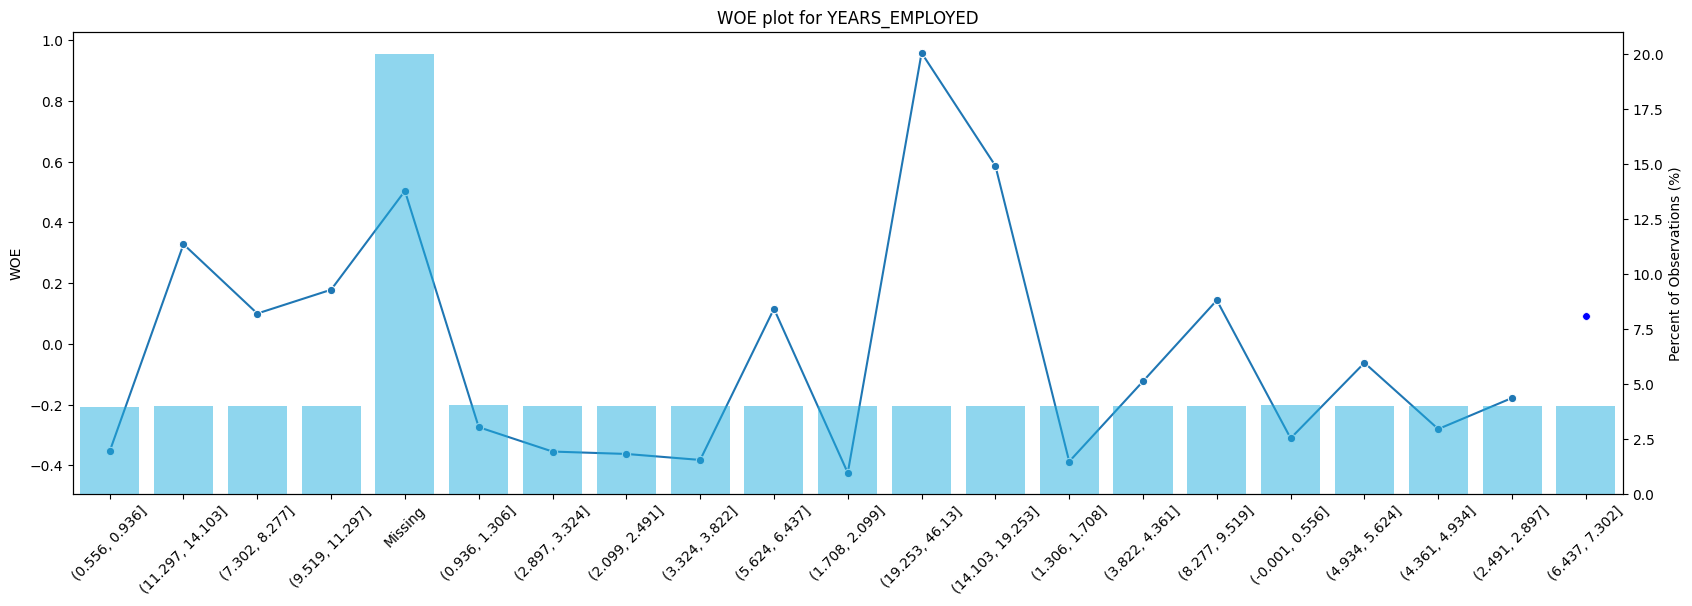

IV for TERM_MONTHS with 19 numeric bins: 0.2969


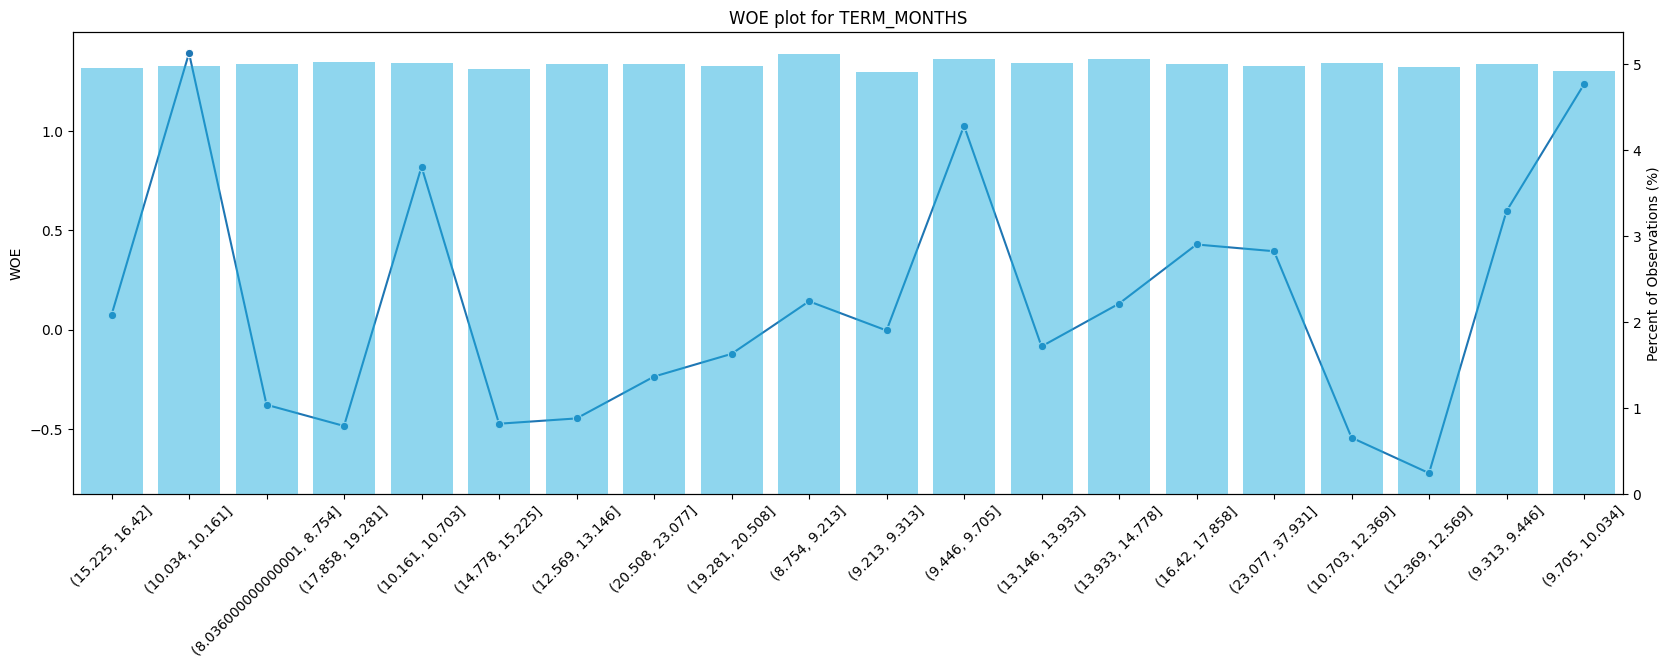

In [23]:
def woe_iv_plot(data, variable_name):
    variable_data = woe_iv(data)
    print('IV for', variable_name, 'with', variable_data.shape[0]-1, 'numeric bins:', round(variable_data.loc[0,'total_IV'],4))
    fig, ax1 = plt.subplots(figsize=(20,6))
    if variable_data['Bin_Range'].isin(['Missing']).sum() > 0:
        sns.lineplot(data = variable_data['WOE'].iloc[0:-1], marker='o', ax=ax1)
    else:
        sns.lineplot(data = variable_data['WOE'], marker='o', ax=ax1)
    plt.xticks(rotation=45)
    if variable_data['Bin_Range'].isin(['Missing']).sum() > 0:
        last_point = len(variable_data['WOE']) - 1
        sns.scatterplot(x=[last_point], y=[variable_data['WOE'][last_point]], color='b', s=30, ax=ax1)
    ax2 = ax1.twinx()
    total_count = variable_data['Count'].sum()
    variable_data['Percent'] = (variable_data['Count'] / total_count) * 100
    sns.barplot(x = variable_data['Bin_Range'].astype(str), y = variable_data['Percent'], alpha=0.5, ax = ax2, color = 'deepskyblue')
    ax2.set_ylabel('Percent of Observations (%)')
    plt.title("WOE plot for " + variable_name)
    plt.show()

for variable in ['YEARS_EMPLOYED', 'TERM_MONTHS']:
    woe_iv_plot(fine_class(train, variable), variable)

### 4.2 Grouping: automatic coarse classing (Weeks 10–11)

`scorecardpy.woebin` fits **automatic coarse bins on training data only**. The result is screened by Information Value (IV), retaining variables with coarse IV ≥ 0.02. Missing values may receive separate bins; binning is checked for sufficient sample size, non-monotonicity and interpretability.

**Automatic bins are the final modelling choice.** A separate manually adjusted bin set is retained only for validation-based comparison. Non-monotonic relationships are not forcibly merged when the risk pattern is substantial and reasonably consistent across training/validation samples.

**WOE sign convention:** The fine-classing demonstration uses `ln(% goods / % bads)`; `scorecardpy` uses `ln(% bads / % goods)`. Consequently **positive scorecardpy WOE indicates higher observed risk**. IV is unchanged by consistent sign reversal.

In [24]:
bins_auto = sc.woebin(train[screened + ['TARGET']], y='TARGET')

def is_monotonic(b):
    r = b.loc[b['bin'] != 'missing', 'badprob'].values
    d = np.diff(r)
    return len(r) < 3 or bool((d >= 0).all() or (d <= 0).all())

auto_summary = pd.DataFrame([dict(variable=k, IV_coarse=v['total_iv'].iloc[0], n_bins=len(v), monotonic=is_monotonic(v),
                                  numeric=pd.api.types.is_numeric_dtype(train[k])) for k, v in bins_auto.items()])
auto_summary = auto_summary.sort_values('IV_coarse', ascending=False).reset_index(drop=True)
print('not monotonic (numeric):', auto_summary.query('~monotonic and numeric')['variable'].tolist())
auto_summary.round(4)

[INFO] creating woe binning ...


Binning on 26784 rows and 50 columns in 00:00:45
not monotonic (numeric): ['TERM_MONTHS', 'CREDIT_TO_GOODS', 'BUR_MEAN_CREDIT', 'AMT_CREDIT', 'BUR_N_CREDIT_TYPES', 'AMT_ANNUITY', 'BUR_N_OPENED_12M', 'BUR_N_ACTIVE', 'LIVINGAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MODE', 'OWN_CAR_AGE', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI']


,variable,IV_coarse,n_bins,monotonic,numeric
0,TERM_MONTHS,0.2271,5,False,True
1,EXT_SOURCE_1,0.1642,6,True,True
2,BUR_SHARE_ACTIVE,0.1484,5,True,True
3,BUR_DEBT_TO_CREDIT,0.1347,5,True,True
4,YEARS_EMPLOYED,0.1323,5,True,True
5,BUR_HISTORY_YEARS,0.1270,5,True,True
6,BUR_MONTHS_SINCE_LAST,0.1010,5,True,True
7,AGE_YEARS,0.1009,4,True,True
8,ORGANIZATION_TYPE,0.0862,3,True,False
9,BUR_N_CLOSED,0.0826,3,True,True


In [25]:
# show the automatic bins of the variables that are not monotonic
for v in auto_summary.query('~monotonic and numeric')['variable']:
    display(bins_auto[v][['variable','bin','count','count_distr','badprob','woe','total_iv']].round(4))

,variable,bin,count,count_distr,badprob,woe,total_iv
0,TERM_MONTHS,"[-inf,9.0)",1899,0.0709,0.0990,0.3033,0.2271
1,TERM_MONTHS,"[9.0,9.5)",3931,0.1468,0.0549,-0.3332,0.2271
2,TERM_MONTHS,"[9.5,10.5)",4566,0.1705,0.0243,-1.1806,0.2271
3,TERM_MONTHS,"[10.5,13.0)",4312,0.1610,0.1206,0.5248,0.2271
4,TERM_MONTHS,"[13.0,inf)",12076,0.4509,0.0807,0.0793,0.2271


,variable,bin,count,count_distr,badprob,woe,total_iv
0,CREDIT_TO_GOODS,"[-inf,1.01)",9395,0.3508,0.0740,-0.0155,0.0719
1,CREDIT_TO_GOODS,"[1.01,1.1)",4308,0.1608,0.0638,-0.1738,0.0719
2,CREDIT_TO_GOODS,"[1.1,1.1700000000000002)",6244,0.2331,0.0538,-0.3553,0.0719
3,CREDIT_TO_GOODS,"[1.1700000000000002,1.2400000000000002)",2773,0.1035,0.0869,0.1597,0.0719
4,CREDIT_TO_GOODS,"[1.2400000000000002,inf)",4064,0.1517,0.1139,0.4604,0.0719


,variable,bin,count,count_distr,badprob,woe,total_iv
0,BUR_MEAN_CREDIT,missing,4301,0.1606,0.1051,0.3698,0.0492
1,BUR_MEAN_CREDIT,"[-inf,40000.0)",1536,0.0573,0.1048,0.3669,0.0492
2,BUR_MEAN_CREDIT,"[40000.0,300000.0)",15747,0.5879,0.0685,-0.0990,0.0492
3,BUR_MEAN_CREDIT,"[300000.0,380000.0)",1383,0.0516,0.0557,-0.3193,0.0492
4,BUR_MEAN_CREDIT,"[380000.0,inf)",3817,0.1425,0.0634,-0.1811,0.0492


,variable,bin,count,count_distr,badprob,woe,total_iv
0,AMT_CREDIT,"[-inf,80000.0)",1770,0.0661,0.0435,-0.5788,0.045
1,AMT_CREDIT,"[80000.0,155000.0)",8824,0.3295,0.0621,-0.2032,0.045
2,AMT_CREDIT,"[155000.0,165000.0)",1432,0.0535,0.1006,0.3206,0.045
3,AMT_CREDIT,"[165000.0,inf)",14758,0.5510,0.0841,0.1236,0.045


,variable,bin,count,count_distr,badprob,woe,total_iv
0,BUR_N_CREDIT_TYPES,"[-inf,1.0)",4301,0.1606,0.1051,0.3698,0.0358
1,BUR_N_CREDIT_TYPES,"[1.0,2.0)",9019,0.3367,0.0638,-0.1752,0.0358
2,BUR_N_CREDIT_TYPES,"[2.0,3.0)",11806,0.4408,0.0728,-0.0321,0.0358
3,BUR_N_CREDIT_TYPES,"[3.0,inf)",1658,0.0619,0.0742,-0.0124,0.0358


,variable,bin,count,count_distr,badprob,woe,total_iv
0,AMT_ANNUITY,"[-inf,7500.0)",3250,0.1213,0.0603,-0.2344,0.0344
1,AMT_ANNUITY,"[7500.0,10500.0)",5704,0.2130,0.0708,-0.0624,0.0344
2,AMT_ANNUITY,"[10500.0,16500.0)",10966,0.4094,0.0770,0.0273,0.0344
3,AMT_ANNUITY,"[16500.0,18500.0)",2253,0.0841,0.1052,0.3708,0.0344
4,AMT_ANNUITY,"[18500.0,21500.0)",1540,0.0575,0.0812,0.0851,0.0344
5,AMT_ANNUITY,"[21500.0,24000.0)",1511,0.0564,0.0463,-0.5129,0.0344
6,AMT_ANNUITY,"[24000.0,inf)",1560,0.0582,0.0859,0.1469,0.0344


... (3 outputs left out)

,variable,bin,count,count_distr,badprob,woe,total_iv
0,YEARS_BEGINEXPLUATATION_MODE,missing,14131,0.5276,0.0823,0.1002,0.0196
1,YEARS_BEGINEXPLUATATION_MODE,"[-inf,0.9770000000000001)",3432,0.1281,0.0763,0.0185,0.0196
2,YEARS_BEGINEXPLUATATION_MODE,"[0.9770000000000001,0.9810000000000001)",2508,0.0936,0.0578,-0.2793,0.0196
3,YEARS_BEGINEXPLUATATION_MODE,"[0.9810000000000001,0.9840000000000001)",1870,0.0698,0.0668,-0.1245,0.0196
4,YEARS_BEGINEXPLUATATION_MODE,"[0.9840000000000001,0.9880000000000001)",2683,0.1002,0.0716,-0.0513,0.0196
5,YEARS_BEGINEXPLUATATION_MODE,"[0.9880000000000001,inf)",2160,0.0806,0.0569,-0.2954,0.0196


,variable,bin,count,count_distr,badprob,woe,total_iv
0,OWN_CAR_AGE,missing,19331,0.7217,0.0785,0.0491,0.0132
1,OWN_CAR_AGE,"[-inf,5.0)",1478,0.0552,0.0643,-0.1665,0.0132
2,OWN_CAR_AGE,"[5.0,12.0)",2609,0.0974,0.0552,-0.3285,0.0132
3,OWN_CAR_AGE,"[12.0,18.0)",1762,0.0658,0.0806,0.0773,0.0132
4,OWN_CAR_AGE,"[18.0,inf)",1604,0.0599,0.0692,-0.0874,0.0132


,variable,bin,count,count_distr,badprob,woe,total_iv
0,YEARS_BUILD_MEDI,missing,18626,0.6954,0.0795,0.0627,0.0117
1,YEARS_BUILD_MEDI,"[-inf,0.6800000000000004)",1795,0.0670,0.0719,-0.0467,0.0117
2,YEARS_BUILD_MEDI,"[0.6800000000000004,0.7400000000000004)",1751,0.0654,0.0594,-0.2507,0.0117
3,YEARS_BUILD_MEDI,"[0.7400000000000004,0.7900000000000005)",1476,0.0551,0.0610,-0.2227,0.0117
4,YEARS_BUILD_MEDI,"[0.7900000000000005,0.8300000000000005)",1414,0.0528,0.0693,-0.0857,0.0117
5,YEARS_BUILD_MEDI,"[0.8300000000000005,inf)",1722,0.0643,0.0627,-0.1927,0.0117


,variable,bin,count,count_distr,badprob,woe,total_iv
0,COMMONAREA_MEDI,missing,19462,0.7266,0.0789,0.0546,0.0112
1,COMMONAREA_MEDI,"[-inf,0.01)",2385,0.0890,0.0600,-0.2406,0.0112
2,COMMONAREA_MEDI,"[0.01,0.025)",1754,0.0655,0.0678,-0.1086,0.0112
3,COMMONAREA_MEDI,"[0.025,0.06)",1833,0.0684,0.0731,-0.0283,0.0112
4,COMMONAREA_MEDI,"[0.06,inf)",1350,0.0504,0.0578,-0.2800,0.0112


### Manually adjusted bins — comparison only

Candidate `breaks_list` boundaries are retained to compare simpler **manually adjusted** bins with the final automatic bins. These adjustments are **not used** by the final selected scorecard, and the adjusted bins are **not all monotonic**.

The final model uses `bins = bins_auto`. The subsequent comparison evaluates whether the additional automatic-bin detail improves validation performance enough to justify its complexity. `TERM_MONTHS` is a loan-to-annuity ratio, not an observed contractual term.

In [26]:
# UPDATED — Automatic binning is now the FINAL modelling approach.
# Both sets of bins are learned from TRAINING data only.

# Retain manually adjusted bins for comparison and audit purposes.
breaks_adj = {
    'CREDIT_TO_GOODS':              [1.14, 1.25],
    'AMT_CREDIT':                   [110000, 180000],
    'AMT_ANNUITY':                  [13000, 16000],
    'REGION_POPULATION_RELATIVE':   [0.021, 0.032],
    'YEARS_BEGINEXPLUATATION_MEDI': [0.977, 0.988],
    'BUR_MAX_CREDIT':               [100000, 2450000],
    'TERM_MONTHS':                  [10.5, 21.5],
}

declared_breaks_adj = breaks_adj.copy()

breaks_adj = {
    k: v for k, v in declared_breaks_adj.items()
    if k in screened
}

# Comparison model only — NOT the final scorecard.
bins_adjusted = (
    sc.woebin(
        train[screened + ['TARGET']],
        y='TARGET',
        breaks_list=breaks_adj
    )
    if breaks_adj else bins_auto
)

# FINAL MODEL: use automatic bins.
bins = bins_auto

print('FINAL BINNING METHOD: AUTOMATIC')
print('Manual adjustments retained only for model comparison.')

# Recalculate coarse-class IV using AUTOMATIC bins.
coarse_summary = pd.DataFrame([
    dict(
        variable=k,
        IV_coarse=v['total_iv'].iloc[0],
        n_bins=len(v),
        monotonic=is_monotonic(v)
    )
    for k, v in bins.items()
]).sort_values(
    'IV_coarse',
    ascending=False
).reset_index(drop=True)

coarse_summary['strength'] = (
    coarse_summary['IV_coarse'].map(iv_strength)
)

print(
    'Non-monotonic automatic variables:',
    coarse_summary.query('~monotonic')['variable'].tolist()
)

# Variable screening is now based on AUTOMATIC-bin IV.
coarse_kept = coarse_summary.loc[
    coarse_summary['IV_coarse'] >= 0.02,
    'variable'
].tolist()

print(
    f'{len(coarse_kept)} variables with automatic-bin '
    'coarse IV >= 0.02'
)

assert bins is bins_auto
assert set(coarse_kept).issubset(set(bins_auto))

display(coarse_summary.round(4))

[INFO] creating woe binning ...


Binning on 26784 rows and 50 columns in 00:00:34
FINAL BINNING METHOD: AUTOMATIC
Manual adjustments retained only for model comparison.
Non-monotonic automatic variables: ['TERM_MONTHS', 'CREDIT_TO_GOODS', 'BUR_MEAN_CREDIT', 'AMT_CREDIT', 'BUR_N_CREDIT_TYPES', 'AMT_ANNUITY', 'BUR_N_OPENED_12M', 'BUR_N_ACTIVE', 'LIVINGAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MODE', 'OWN_CAR_AGE', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI']
41 variables with automatic-bin coarse IV >= 0.02


,variable,IV_coarse,n_bins,monotonic,strength
0,TERM_MONTHS,0.2271,5,False,medium
1,EXT_SOURCE_1,0.1642,6,True,medium
2,BUR_SHARE_ACTIVE,0.1484,5,True,medium
3,BUR_DEBT_TO_CREDIT,0.1347,5,True,medium
4,YEARS_EMPLOYED,0.1323,5,True,medium
5,BUR_HISTORY_YEARS,0.1270,5,True,medium
6,BUR_MONTHS_SINCE_LAST,0.1010,5,True,medium
7,AGE_YEARS,0.1009,4,True,medium
8,ORGANIZATION_TYPE,0.0862,3,True,weak
9,BUR_N_CLOSED,0.0826,3,True,weak


In [27]:
# NEW — coarse-grouping verification
assert set(coarse_kept).issubset(set(bins))
assert np.isfinite(coarse_summary['IV_coarse']).all(), 'Invalid coarse-class IV'
assert all(coarse_summary.set_index('variable').loc[coarse_kept, 'IV_coarse'] >= .02)
print('COARSE IV AUDIT: training-derived bins, finite IV and screened membership confirmed')
print('Non-monotonic numeric exceptions (review for explainability):',
      coarse_summary.loc[~coarse_summary['monotonic'], 'variable'].tolist())

COARSE IV AUDIT: training-derived bins, finite IV and screened membership confirmed
Non-monotonic numeric exceptions (review for explainability): ['TERM_MONTHS', 'CREDIT_TO_GOODS', 'BUR_MEAN_CREDIT', 'AMT_CREDIT', 'BUR_N_CREDIT_TYPES', 'AMT_ANNUITY', 'BUR_N_OPENED_12M', 'BUR_N_ACTIVE', 'LIVINGAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MODE', 'OWN_CAR_AGE', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI']


In [28]:
# UPDATED — Display the MANUALLY ADJUSTED bins
# retained for comparison, not final modelling.

for v in breaks_adj:
    if v in bins_adjusted:
        print(f'\nManually adjusted bins: {v}')

        display(
            bins_adjusted[v][
                [
                    'variable',
                    'bin',
                    'count',
                    'count_distr',
                    'badprob',
                    'woe',
                    'total_iv'
                ]
            ].round(4)
        )


Manually adjusted bins: CREDIT_TO_GOODS


,variable,bin,count,count_distr,badprob,woe,total_iv
0,CREDIT_TO_GOODS,"[-inf,1.14)",18829,0.7030,0.0665,-0.1293,0.0503
1,CREDIT_TO_GOODS,"[1.14,1.25)",3891,0.1453,0.0756,0.0074,0.0503
2,CREDIT_TO_GOODS,"[1.25,inf)",4064,0.1517,0.1139,0.4604,0.0503



Manually adjusted bins: AMT_CREDIT


,variable,bin,count,count_distr,badprob,woe,total_iv
0,AMT_CREDIT,"[-inf,110000.0)",4585,0.1712,0.0523,-0.3845,0.0328
1,AMT_CREDIT,"[110000.0,180000.0)",9258,0.3457,0.0716,-0.0505,0.0328
2,AMT_CREDIT,"[180000.0,inf)",12941,0.4832,0.0855,0.1423,0.0328



Manually adjusted bins: AMT_ANNUITY


,variable,bin,count,count_distr,badprob,woe,total_iv
0,AMT_ANNUITY,"[-inf,13000.0)",14571,0.5440,0.0712,-0.0562,0.0037
1,AMT_ANNUITY,"[13000.0,16000.0)",4573,0.1707,0.0783,0.0458,0.0037
2,AMT_ANNUITY,"[16000.0,inf)",7640,0.2852,0.0804,0.0743,0.0037



Manually adjusted bins: REGION_POPULATION_RELATIVE


,variable,bin,count,count_distr,badprob,woe,total_iv
0,REGION_POPULATION_RELATIVE,"[-inf,0.021)",17129,0.6395,0.0808,0.0801,0.017
1,REGION_POPULATION_RELATIVE,"[0.021,0.032)",7100,0.2651,0.0689,-0.0925,0.017
2,REGION_POPULATION_RELATIVE,"[0.032,inf)",2555,0.0954,0.0536,-0.3591,0.017



Manually adjusted bins: TERM_MONTHS


,variable,bin,count,count_distr,badprob,woe,total_iv
0,TERM_MONTHS,"[-inf,10.5)",10396,0.3881,0.0495,-0.4425,0.1134
1,TERM_MONTHS,"[10.5,21.5)",14558,0.5435,0.0958,0.2671,0.1134
2,TERM_MONTHS,"[21.5,inf)",1830,0.0683,0.0546,-0.3390,0.1134


## Part 5. Logistic regression and model performance
### 5.1 Logistic regression with WoE encoding (Week 11 lab)

`sc.woebin_ply` maps each input value into the training-derived bin's WoE. Before fitting:

* **WoE redundancy screening:** Within pairs with absolute WoE correlation > 0.8, retain the candidate with stronger training IV.
* **Validation-based forward selection:** Add the predictor that most improves validation Gini, stopping at 15 variables or when an additional variable improves validation Gini by less than 0.002.
* **Coefficient check:** A candidate is retained only when its fitted coefficients are at least 0.1 under the `scorecardpy` positive-risk WoE convention. This is an interpretability constraint, not a universal statistical rule.

The regression coefficients are fitted on training data; **validation outcomes guide which predictors enter the final model**. Final test results are reported separately.

In [29]:
# UPDATED — WOE fit on train; use VALIDATION, never test, during forward selection.
train_woe = sc.woebin_ply(train[coarse_kept + ['TARGET']], bins)
valid_woe = sc.woebin_ply(valid[coarse_kept + ['TARGET']], bins)
# Scorecardpy may return a fresh RangeIndex; attach input indexes to preserve applicant alignment.
train_woe.index, valid_woe.index = train.index, valid.index
y_train, y_valid = train_woe['TARGET'], valid_woe['TARGET']

iv_of = coarse_summary.set_index('variable')['IV_coarse']
woe_cols = sorted([c for c in train_woe.columns if c.endswith('_woe')],
                  key=lambda c: -iv_of[c[:-4]])
wcor = train_woe[woe_cols].corr().abs()
candidates = []
for c in woe_cols:
    if all(wcor.loc[c, k] <= 0.8 for k in candidates):
        candidates.append(c)
print(f'{len(woe_cols)} WOE variables -> {len(candidates)} candidates after redundancy screening')

def gini(y, p):
    return 2 * metrics.roc_auc_score(y, p) - 1

def fit(cols):
    m = linear_model.LogisticRegression(max_iter=1000)
    return m.fit(train_woe[cols], y_train)

MIN_COEF = 0.1
selected, path, best_g = [], [], 0.0
while len(selected) < 15:
    best = None
    for c in candidates:
        if c in selected:
            continue
        trial = selected + [c]
        candidate_model = fit(trial)
        if (candidate_model.coef_[0] < MIN_COEF).any():
            continue
        val_g = gini(y_valid, candidate_model.predict_proba(valid_woe[trial])[:, 1])
        if best is None or val_g > best[1]:
            best = (c, val_g, candidate_model)
    if best is None or best[1] - best_g < 0.002:
        break
    c, best_g, chosen_lr = best
    selected.append(c)
    path.append(dict(step=len(selected), added=c[:-4],
                     gini_train=gini(y_train, chosen_lr.predict_proba(train_woe[selected])[:, 1]),
                     gini_validation=best_g))
path = pd.DataFrame(path)
assert selected, 'No variables passed forward selection; re-evaluate positive coefficient rule.'
path.to_csv('g7_forward_selection_validation.csv', index=False)
display(path.round(4))

[INFO] converting into woe values ...


[INFO] converting into woe values ...


41 WOE variables -> 32 candidates after redundancy screening


,step,added,gini_train,gini_validation
0,1,TERM_MONTHS,0.2318,0.2327
1,2,YEARS_EMPLOYED,0.3014,0.3096
2,3,BUR_SHARE_ACTIVE,0.3530,0.3460
3,4,EXT_SOURCE_1,0.3896,0.3722
4,5,NAME_EDUCATION_TYPE,0.4010,0.3883
5,6,BUR_N_OPENED_12M,0.4082,0.3982
6,7,BUR_MAX_AMT_OVERDUE,0.4170,0.4064
7,8,YEARS_ID_PUBLISH,0.4227,0.4134
8,9,OCCUPATION_TYPE,0.4268,0.4195
9,10,CREDIT_TO_GOODS,0.4329,0.4246


## Part 6. Model tuning

Candidate configurations are compared using **validation data**, not final test outcomes:

1. **Number of predictors:** Compare steps on the validation-based forward-selection path and the full candidate set.
2. **Binning approach:** Compare the final **automatic bins** with the manually adjusted-bin alternative using the same selected predictors. The adjusted version is **not guaranteed monotonic**.
3. **Class weighting:** Compare standard logistic regression with `class_weight='balanced'`; the latter changes predicted probability calibration and is not chosen merely for class imbalance.
4. **Model suitability:** Review validation Gini, coefficient signs, calibration, bin sample sizes and interpretability.

Automatic bins are the proposed final configuration; the independent test sample is for subsequent reporting, not choosing between configurations.

In [30]:
# UPDATED — Model tuning uses VALIDATION only.
# Automatic bins are proposed for the final model.

def validation_gini(bins_used, cols, **lr_args):
    names = [c[:-4] for c in cols]

    trw = sc.woebin_ply(
        train[names + ['TARGET']],
        bins_used
    )

    vaw = sc.woebin_ply(
        valid[names + ['TARGET']],
        bins_used
    )

    m = linear_model.LogisticRegression(
        max_iter=1000,
        **lr_args
    )

    m.fit(trw[cols], trw['TARGET'])

    p_tr = m.predict_proba(trw[cols])[:, 1]
    p_va = m.predict_proba(vaw[cols])[:, 1]

    return dict(
        n_vars=len(cols),
        gini_train=gini(trw['TARGET'], p_tr),
        gini_validation=gini(vaw['TARGET'], p_va),
        wrong_sign=int((m.coef_[0] <= 0).sum()),
        mean_predicted_PD_validation=p_va.mean(),
        validation_bad_rate=float(vaw['TARGET'].mean())
    )

# 'selected' is now obtained from automatic-bin forward selection.
tuning = pd.DataFrame({

    'Selected variables, automatic bins (proposed)':
        validation_gini(bins_auto, selected),

    'Selected variables, adjusted bins':
        validation_gini(bins_adjusted, selected),

    'First 5 selected variables':
        validation_gini(bins_auto, selected[:5]),

    'First 10 selected variables':
        validation_gini(bins_auto, selected[:10]),

    'All candidate variables':
        validation_gini(bins_auto, candidates),

    "Selected + class_weight='balanced'":
        validation_gini(
            bins_auto,
            selected,
            class_weight='balanced'
        ),

}).T

tuning['PD_calibration_gap'] = (
    tuning['mean_predicted_PD_validation']
    - tuning['validation_bad_rate']
).abs()

print('PROPOSED FINAL MODEL: AUTOMATIC BINS')
print('Number of selected variables:', len(selected))

tuning.to_csv('g7_tuning_validation.csv')

display(tuning.round(4))

[INFO] converting into woe values ...


[INFO] converting into woe values ...


[INFO] converting into woe values ...


[INFO] converting into woe values ...


[INFO] converting into woe values ...


[INFO] converting into woe values ...


... (4 outputs left out)

[INFO] converting into woe values ...


[INFO] converting into woe values ...


PROPOSED FINAL MODEL: AUTOMATIC BINS
Number of selected variables: 14


,n_vars,gini_train,gini_validation,wrong_sign,mean_predicted_PD_validation,validation_bad_rate,PD_calibration_gap
"Selected variables, automatic bins (proposed)",14.0,0.4500,0.4383,0.0,0.0759,0.0749,0.0010
"Selected variables, adjusted bins",14.0,0.4332,0.4245,0.0,0.0755,0.0749,0.0005
First 5 selected variables,5.0,0.4010,0.3883,0.0,0.0754,0.0749,0.0004
First 10 selected variables,10.0,0.4329,0.4246,0.0,0.0756,0.0749,0.0007
All candidate variables,32.0,0.4745,0.4311,5.0,0.0759,0.0749,0.0010
Selected + class_weight='balanced',14.0,0.4499,0.4382,0.0,0.4372,0.0749,0.3623


In [31]:
# NEW — Compare adjusted vs automatic bins using VALIDATION ONLY.
# This does not change the final model or use the test set.

raw_vars = [c[:-4] for c in selected]
yv = valid['TARGET'].to_numpy()
principal = loan_info.loc[valid.index, 'AMT_CREDIT'].to_numpy(dtype=float)

# Match the hypothetical financial assumptions in Part 7.
def scenario_interest(principal, apr, months=24):
    r = apr / 12
    return principal * r / (1 - (1 + r) ** (-months)) * months - principal

net_interest = (
    scenario_interest(principal, 0.15)
    - scenario_interest(principal, 0.05)
)
scenario_profit = np.where(yv == 0, net_interest, -0.70 * principal)

results = []

for label, bins_used in [
    ('Adjusted', bins_adjusted),
    ('Automatic', bins_auto)
]:

    # Transform train and validation using training-derived bins.
    trw = sc.woebin_ply(train[raw_vars + ['TARGET']], bins_used)
    vaw = sc.woebin_ply(valid[raw_vars + ['TARGET']], bins_used)

    trw.index, vaw.index = train.index, valid.index

    # Fit the same 14-variable logistic regression.
    model_cmp = linear_model.LogisticRegression(max_iter=1000)
    model_cmp.fit(trw[selected], trw['TARGET'])

    p_val = model_cmp.predict_proba(vaw[selected])[:, 1]

    # Construct an actual scorecard for each binning method.
    card_cmp = sc.scorecard(
        bins_used, model_cmp, selected,
        points0=600,
        odds0=1/19,
        pdo=20,
        basepoints_eq0=True
    )

    score_val = sc.scorecard_ply(valid, card_cmp)['score'].to_numpy()

    # Scorecard-level discrimination.
    fpr, tpr, _ = metrics.roc_curve(yv, -score_val)
    auc = metrics.roc_auc_score(yv, -score_val)

    # Validation-only profitability comparison.
    cutoffs_cmp = np.arange(
        int(np.floor(score_val.min() / 5) * 5),
        int(np.ceil(score_val.max() / 5) * 5) + 5,
        5
    )

    profits = np.array([
        scenario_profit[score_val >= c].sum() / 1e6
        for c in cutoffs_cmp
    ])

    best_index = int(profits.argmax())

    # Bin-quality checks.
    small_bins = 0
    nonmono = 0
    total_bins = 0

    for name in raw_vars:
        table = bins_used[name]
        total_bins += len(table)

        non_missing = table.loc[
            ~table['bin'].astype(str).str.contains(
                'missing', case=False
            )
        ]

        small_bins += int(
            (non_missing['count_distr'] < 0.05).sum()
        )

        if pd.api.types.is_numeric_dtype(train[name]):
            nonmono += int(not is_monotonic(table))

    results.append({
        'method': label,
        'validation_AUC_score': auc,
        'validation_Gini_score': 2 * auc - 1,
        'validation_KS_score': np.max(tpr - fpr),
        'validation_Brier_probability':
            metrics.brier_score_loss(yv, p_val),
        'calibration_gap': abs(p_val.mean() - yv.mean()),
        'wrong_sign_coef': int(
            (model_cmp.coef_[0] <= 0).sum()
        ),
        'total_bins_14_vars': total_bins,
        'nonmonotonic_numeric_vars': nonmono,
        'nonmissing_bins_under_5pct': small_bins,
        'best_validation_cutoff': int(
            cutoffs_cmp[best_index]
        ),
        'best_validation_profit_m': profits[best_index]
    })

comparison = pd.DataFrame(results).set_index('method')

print('VALIDATION COMPARISON — same 14 predictors')
display(comparison.round(4))

# Compare bin structure and IV for each selected variable.
bin_details = pd.DataFrame([{
    'variable': name,
    'adjusted_bins': len(bins_adjusted[name]),
    'automatic_bins': len(bins_auto[name]),
    'adjusted_IV': float(
        bins_adjusted[name]['total_iv'].iloc[0]
    ),
    'automatic_IV': float(
        bins_auto[name]['total_iv'].iloc[0]
    ),
    'adjusted_monotonic': is_monotonic(bins_adjusted[name]),
    'automatic_monotonic': is_monotonic(bins_auto[name])
} for name in raw_vars])

print('BIN QUALITY — training data')
display(bin_details.round(4))

# Inspect the most important binning difference.
print('TERM_MONTHS (loan-to-annuity ratio)')

for label, bin_set in [
    ('Adjusted', bins_adjusted),
    ('Automatic', bins_auto)
]:
    print(label)
    display(
        bin_set['TERM_MONTHS'][
            ['bin', 'count', 'count_distr', 'badprob', 'total_iv']
        ].round(4)
    )

comparison.to_csv('g7_binning_comparison_validation.csv')
bin_details.to_csv(
    'g7_binning_details_validation.csv',
    index=False
)

[INFO] converting into woe values ...


[INFO] converting into woe values ...


[INFO] converting into woe values ...


[INFO] converting into woe values ...


VALIDATION COMPARISON — same 14 predictors


,validation_AUC_score,validation_Gini_score,validation_KS_score,validation_Brier_probability,calibration_gap,wrong_sign_coef,total_bins_14_vars,nonmonotonic_numeric_vars,nonmissing_bins_under_5pct,best_validation_cutoff,best_validation_profit_m
method,,,,,,,,,,,
Adjusted,0.7127,0.4253,0.3301,0.0664,0.0005,0,57,3,0,565,52.2310
Automatic,0.7194,0.4387,0.3506,0.0661,0.0010,0,62,5,0,565,52.4685


... (2 outputs left out)

TERM_MONTHS (loan-to-annuity ratio)
Adjusted


,bin,count,count_distr,badprob,total_iv
0,"[-inf,10.5)",10396,0.3881,0.0495,0.1134
1,"[10.5,21.5)",14558,0.5435,0.0958,0.1134
2,"[21.5,inf)",1830,0.0683,0.0546,0.1134


Automatic


,bin,count,count_distr,badprob,total_iv
0,"[-inf,9.0)",1899,0.0709,0.0990,0.2271
1,"[9.0,9.5)",3931,0.1468,0.0549,0.2271
2,"[9.5,10.5)",4566,0.1705,0.0243,0.2271
3,"[10.5,13.0)",4312,0.1610,0.1206,0.2271
4,"[13.0,inf)",12076,0.4509,0.0807,0.2271


In [32]:
# Check whether automatic TERM_MONTHS risk patterns
# remain consistent between training and validation.

edges = [-np.inf, 9.0, 9.5, 10.5, 13.0, np.inf]
labels = ['<9', '9–9.5', '9.5–10.5', '10.5–13', '>=13']

def check_term_bins(data):
    d = data[['TERM_MONTHS', 'TARGET']].copy()

    d['term_bin'] = pd.cut(
        d['TERM_MONTHS'],
        bins=edges,
        labels=labels,
        right=False
    )

    return d.groupby('term_bin', observed=True)['TARGET'].agg(
        applicants='size',
        bads='sum',
        bad_rate='mean'
    )

train_check = check_term_bins(train)
valid_check = check_term_bins(valid)

term_stability = train_check.join(
    valid_check,
    lsuffix='_train',
    rsuffix='_valid'
)

term_stability['bad_rate_difference_pp'] = (
    term_stability['bad_rate_valid']
    - term_stability['bad_rate_train']
) * 100

display(term_stability.round(4))

,applicants_train,bads_train,bad_rate_train,applicants_valid,bads_valid,bad_rate_valid,bad_rate_difference_pp
term_bin,,,,,,,
<9,1899,188,0.0990,398,34,0.0854,-1.3572
9–9.5,3931,216,0.0549,842,55,0.0653,1.0373
9.5–10.5,4566,111,0.0243,999,23,0.0230,-0.1287
10.5–13,4312,520,0.1206,934,121,0.1296,0.8957
>=13,12076,975,0.0807,2566,197,0.0768,-0.3965


In [33]:
# NEW — Investigate the sharp TERM_MONTHS bad-rate jump.
# TERM_MONTHS = AMT_CREDIT / AMT_ANNUITY.
# Use TRAIN and VALIDATION only.

import numpy as np
import pandas as pd

def investigate_term_jump(data, dataset_name):

    # Focus on the adjacent bins with the largest risk difference.
    d = data.loc[
        (data['TERM_MONTHS'] >= 9.5) &
        (data['TERM_MONTHS'] < 13.0)
    ].copy()

    d['term_group'] = np.where(
        d['TERM_MONTHS'] < 10.5,
        '9.5-10.5',
        '10.5-13.0'
    )

    print(f'\n{"=" * 65}')
    print(f'{dataset_name}: TERM_MONTHS DIAGNOSTICS')
    print("=" * 65)

    # 1. Compare characteristics of the two groups.
    print('\n1. APPLICANT PROFILE COMPARISON')

    profile = d.groupby('term_group').agg(
        applicants=('TARGET', 'size'),
        bad_cases=('TARGET', 'sum'),
        bad_rate=('TARGET', 'mean'),
        median_loan=('AMT_CREDIT', 'median'),
        median_annuity=('AMT_ANNUITY', 'median'),
        median_income=('AMT_INCOME_TOTAL', 'median'),
        median_annuity_income=('ANNUITY_TO_INCOME', 'median'),
        median_age=('AGE_YEARS', 'median')
    )

    display(profile.round(4))

    # 2. Inspect narrower intervals near the 10.5 boundary.
    print('\n2. LOCAL BAD RATES AROUND 10.5')

    edges = [
        9.5, 9.75, 10.0, 10.25, 10.5,
        10.75, 11.0, 11.25, 11.5, 12.0, 13.0
    ]

    d['narrow_bin'] = pd.cut(
        d['TERM_MONTHS'],
        bins=edges,
        right=False
    )

    local = d.groupby('narrow_bin', observed=True)['TARGET'].agg(
        applicants='size',
        bad_cases='sum',
        bad_rate='mean'
    )

    display(local.round(4))

    # 3. Compare the two groups within similar loan amounts.
    print('\n3. BAD RATES WITHIN LOAN-AMOUNT BANDS')

    d['loan_band'] = pd.cut(
        d['AMT_CREDIT'],
        bins=[50000, 100000, 150000, 200000, 250001],
        right=False
    )

    stratified = (
        d.groupby(
            ['loan_band', 'term_group'],
            observed=True
        )['TARGET']
        .agg(
            applicants='size',
            bad_cases='sum',
            bad_rate='mean'
        )
    )

    display(stratified.round(4))


investigate_term_jump(train, 'TRAINING')
investigate_term_jump(valid, 'VALIDATION')


TRAINING: TERM_MONTHS DIAGNOSTICS

1. APPLICANT PROFILE COMPARISON


,applicants,bad_cases,bad_rate,median_loan,median_annuity,median_income,median_annuity_income,median_age
term_group,,,,,,,,
10.5-13.0,4312,520,0.1206,180000.0,14946.75,112500.0,0.1182,37.3689
9.5-10.5,4566,111,0.0243,148500.0,14872.50,112500.0,0.1355,49.3963



2. LOCAL BAD RATES AROUND 10.5


,applicants,bad_cases,bad_rate
narrow_bin,,,
"[9.5, 9.75)",976,25,0.0256
"[9.75, 10.0)",718,12,0.0167
"[10.0, 10.25)",2463,51,0.0207
"[10.25, 10.5)",409,23,0.0562
"[10.5, 10.75)",412,19,0.0461
"[10.75, 11.0)",540,80,0.1481
"[11.25, 11.5)",32,4,0.1250
"[11.5, 12.0)",266,32,0.1203
"[12.0, 13.0)",3062,385,0.1257



3. BAD RATES WITHIN LOAN-AMOUNT BANDS


applicants  bad_cases  bad_rate
loan_band        term_group                                 
[50000, 100000)  10.5-13.0          414         45    0.1087
                 9.5-10.5           984         16    0.0163
[100000, 150000) 10.5-13.0         1003         93    0.0927
                 9.5-10.5          1365         36    0.0264
[150000, 200000) 10.5-13.0         1136        146    0.1285
                 9.5-10.5           908         24    0.0264
[200000, 250001) 10.5-13.0         1759        236    0.1342
                 9.5-10.5          1309         35    0.0267

... (2 outputs left out)


2. LOCAL BAD RATES AROUND 10.5


,applicants,bad_cases,bad_rate
narrow_bin,,,
"[9.5, 9.75)",215,6,0.0279
"[9.75, 10.0)",156,5,0.0321
"[10.0, 10.25)",542,9,0.0166
"[10.25, 10.5)",86,3,0.0349
"[10.5, 10.75)",75,5,0.0667
"[10.75, 11.0)",113,18,0.1593
"[11.25, 11.5)",5,0,0.0000
"[11.5, 12.0)",60,5,0.0833
"[12.0, 13.0)",681,93,0.1366



3. BAD RATES WITHIN LOAN-AMOUNT BANDS


applicants  bad_cases  bad_rate
loan_band        term_group                                 
[50000, 100000)  10.5-13.0           78          7    0.0897
                 9.5-10.5           243          3    0.0123
[100000, 150000) 10.5-13.0          217         20    0.0922
                 9.5-10.5           297          6    0.0202
[150000, 200000) 10.5-13.0          242         24    0.0992
                 9.5-10.5           180          3    0.0167
[200000, 250001) 10.5-13.0          397         70    0.1763
                 9.5-10.5           279         11    0.0394

In [34]:
# UPDATED — Final model-selection audit.
# Choose the automatic-bin model using VALIDATION evidence only.

chosen_model_description = (
    'Selected variables, automatic bins (proposed)'
)

proposed = tuning.loc[chosen_model_description]

eligible = tuning[
    (tuning['wrong_sign'] == 0) &
    (tuning['PD_calibration_gap'] <= 0.03)
]

assert int(proposed['wrong_sign']) == 0, (
    'Automatic-bin model has invalid coefficient signs.'
)

assert proposed['PD_calibration_gap'] <= 0.03, (
    'Automatic-bin model failed the calibration-gap check.'
)

if not eligible.empty:
    ranked = eligible.sort_values(
        'gini_validation',
        ascending=False
    )

    top_name = ranked.index[0]
    top_eligible = ranked.iloc[0]

    gap = float(
        top_eligible['gini_validation']
        - proposed['gini_validation']
    )

    print('Best eligible validation model:', top_name)

    print(
        'Validation Gini advantage over proposed:',
        round(gap, 4)
    )

    if gap > 0.02:
        print(
            'GROUP REVIEW REQUIRED: another eligible '
            'model has a materially higher validation Gini.'
        )

print('=' * 65)
print('FINAL MODEL SELECTION')
print('=' * 65)

print('Binning method: AUTOMATIC')
print('Selected variables:', len(selected))
print('Validation Gini:', round(
    proposed['gini_validation'], 4
))
print('Wrong-sign coefficients:', int(
    proposed['wrong_sign']
))
print('Calibration gap:', round(
    proposed['PD_calibration_gap'], 4
))

assert bins is bins_auto

print('MODEL CONFIGURATION LOCKED FOR THIS RUN')

Best eligible validation model: Selected variables, automatic bins (proposed)
Validation Gini advantage over proposed: 0.0
FINAL MODEL SELECTION
Binning method: AUTOMATIC
Selected variables: 14
Validation Gini: 0.4383
Wrong-sign coefficients: 0
Calibration gap: 0.001
MODEL CONFIGURATION LOCKED FOR THIS RUN


### Reading the tuning and binning comparisons

* **Final configuration:** 14 selected variables with **automatic `sc.woebin` bins**, selected using training-data model fitting and validation-based feature selection.
* **Validation model-probability Gini:** automatic **0.4383** vs manually adjusted **0.4245**, for the same 14 predictors.
* **Validation rounded-scorecard metrics:** automatic **AUC 0.7194, Gini 0.4387, KS 35.06%**; adjusted **AUC 0.7127, Gini 0.4253, KS 33.01%**. Small numerical differences between probability-based and integer-score-based Gini are due to score rounding.
* **Bin-complexity trade-off:** automatic **62** bins vs adjusted **57** among the 14 selected variables; **5** vs **3** non-monotonic numeric variables, respectively. Neither has non-missing bins below the checked 5% population share.
* **`TERM_MONTHS` evidence:** automatic IV **0.2271** with five bins vs adjusted IV **0.1134** with three bins. The automatic bins preserve substantial non-monotonic bad-rate differences: the 9.5–10.5 group has **2.43%** bads in training and **2.30%** in validation, while the 10.5–13 group has **12.06%** and **12.96%**, respectively. These are associations, not causal effects or confirmed contractual-tenure differences.
* **Model complexity:** the 14-variable model is preferred to all 32 WoE candidates, whose validation Gini is lower (**0.4311**) despite greater training Gini (**0.4745**) and five wrong-sign coefficients.
* **Class weighting:** `class_weight='balanced'` produces a similar validation ranking (Gini **0.4382**) but a mean predicted payment-difficulty probability around **43.7%**, far above the observed **7.49%**, so it is not used for the probability-based lending scenarios.

The automatic approach has a modest validation advantage, not a proven long-term stability or causal advantage. The test set remains reserved for final reporting of this selected model.

In [35]:
# UPDATED — AFTER model choice, fit on train and evaluate on the held-out test data.
test_woe = sc.woebin_ply(test[coarse_kept + ['TARGET']], bins)
test_woe.index = test.index
y_test = test_woe['TARGET']
X_train, X_valid, X_test = train_woe[selected], valid_woe[selected], test_woe[selected]
lr = linear_model.LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
coefs = pd.Series(np.concatenate([lr.intercept_, lr.coef_[0]]),
                  index=np.concatenate([['intercept'], lr.feature_names_in_]))
coef_table = pd.DataFrame({'coef': coefs, 'IV': [np.nan] + [iv_of[c[:-4]] for c in selected]})
assert np.isfinite(lr.coef_).all() and np.isfinite(lr.intercept_).all()
assert len(lr.feature_names_in_) == len(selected)
display(coef_table.round(4))

[INFO] converting into woe values ...


,coef,IV
intercept,-2.5152,NaN
TERM_MONTHS_woe,0.6530,0.2271
YEARS_EMPLOYED_woe,0.4907,0.1323
BUR_SHARE_ACTIVE_woe,0.7460,0.1484
EXT_SOURCE_1_woe,0.6602,0.1642
NAME_EDUCATION_TYPE_woe,0.8101,0.0313
BUR_N_OPENED_12M_woe,1.0295,0.0281
BUR_MAX_AMT_OVERDUE_woe,0.8547,0.0441
YEARS_ID_PUBLISH_woe,0.4952,0.0518
OCCUPATION_TYPE_woe,0.3912,0.0771


### 6.2 Final model, scorecard and test performance (Week 11 lab)

Scorecard scaling: **600 points = 19:1 good-to-bad odds** (equivalently **5% model-implied probability of `TARGET = 1`**) and **PDO = 20** points for doubling the good-to-bad odds. With `basepoints_eq0=True`, scorecard base points are distributed across the selected variables.

`TARGET = 1` records **payment difficulties** in the historical dataset; it is not a verified realised default or loss. Integer score rounding may introduce small differences from logistic probabilities.

In [36]:
# UPDATED — one consistent scorecard for train / validation / test.
card = sc.scorecard(bins, lr, X_train.columns, points0=600, odds0=1/19,
                    pdo=20, basepoints_eq0=True)
scorecard_table = pd.concat(card.values(), ignore_index=True).query(
    "variable != 'basepoints'")[['variable', 'bin', 'points']]
scorecard_table.to_csv('g7_scorecard_points.csv', index=False)
train_score = sc.scorecard_ply(train, card)
valid_score = sc.scorecard_ply(valid, card)
test_score = sc.scorecard_ply(test, card)
train_score.index, valid_score.index, test_score.index = train.index, valid.index, test.index
print('Score range:', int(min(train_score.score.min(), valid_score.score.min(), test_score.score.min())),
      'to', int(max(train_score.score.max(), valid_score.score.max(), test_score.score.max())))
assert len(train_score)==len(train) and len(valid_score)==len(valid) and len(test_score)==len(test)
display(scorecard_table)

Score range: 514 to 706


,variable,bin,points
1,TERM_MONTHS,"[-inf,9.0)",36.0
2,TERM_MONTHS,"[9.0,9.5)",48.0
3,TERM_MONTHS,"[9.5,10.5)",64.0
4,TERM_MONTHS,"[10.5,13.0)",32.0
5,TERM_MONTHS,"[13.0,inf)",40.0
...,...,...,...
58,AMT_CREDIT,"[165000.0,inf)",40.0
59,NAME_FAMILY_STATUS,Widow,50.0
60,NAME_FAMILY_STATUS,Married,44.0
61,NAME_FAMILY_STATUS,Separated,42.0


In [37]:
# bins of the final model with their points (the table for the slides)
final_bins = pd.concat([bins[c[:-4]] for c in selected], ignore_index=True)
final_bins = final_bins.merge(scorecard_table, on=['variable', 'bin'], how='left')
final_bins = final_bins[['variable', 'bin', 'count', 'count_distr', 'badprob', 'woe', 'total_iv', 'points']]
final_bins.to_csv('g7_final_bins_and_points.csv', index=False)
final_bins.round(4)

,variable,bin,count,count_distr,badprob,woe,total_iv,points
0,TERM_MONTHS,"[-inf,9.0)",1899,0.0709,0.0990,0.3033,0.2271,36.0
1,TERM_MONTHS,"[9.0,9.5)",3931,0.1468,0.0549,-0.3332,0.2271,48.0
2,TERM_MONTHS,"[9.5,10.5)",4566,0.1705,0.0243,-1.1806,0.2271,64.0
3,TERM_MONTHS,"[10.5,13.0)",4312,0.1610,0.1206,0.5248,0.2271,32.0
4,TERM_MONTHS,"[13.0,inf)",12076,0.4509,0.0807,0.0793,0.2271,40.0
...,...,...,...,...,...,...,...,...
57,AMT_CREDIT,"[165000.0,inf)",14758,0.5510,0.0841,0.1236,0.0450,40.0
58,NAME_FAMILY_STATUS,Widow,1645,0.0614,0.0474,-0.4885,0.0408,50.0
59,NAME_FAMILY_STATUS,Married,15632,0.5836,0.0682,-0.1031,0.0408,44.0
60,NAME_FAMILY_STATUS,Separated,2105,0.0786,0.0732,-0.0275,0.0408,42.0


In [38]:
# NEW — verify scorecard points can be reconciled with final training-derived bins.
assert not scorecard_table['points'].isna().any(), 'Missing points in scorecard'
assert not final_bins['points'].isna().any(), 'A final model bin has no points'
assert set(v[:-4] for v in selected) == set(scorecard_table['variable'])
print('SCORECARD AUDIT: all selected predictor bins have points')

SCORECARD AUDIT: all selected predictor bins have points


**Ranking performance (AUC, Gini, KS):** These metrics are reported separately for training, validation and test data. Similar values provide evidence against **severe** overfitting on these splits, but they do not prove perfect generalisation or rule out selection bias, especially for real medical-purpose loans.

In [39]:
def ks_stat(y, score):
    d = pd.DataFrame({'y': np.asarray(y), 's': np.asarray(score)}).groupby('s')['y'].agg(
        bads='sum', n='size').cumsum()
    cum_bad = d['bads'] / d['bads'].iloc[-1]
    cum_good = (d['n'] - d['bads']) / (d['n'] - d['bads']).iloc[-1]
    return (cum_bad - cum_good).abs().max()

perf = pd.DataFrame({
    'AUC': [metrics.roc_auc_score(y_train, -train_score.score),
            metrics.roc_auc_score(y_valid, -valid_score.score),
            metrics.roc_auc_score(y_test, -test_score.score)],
    'Gini': [gini(y_train, -train_score.score),
             gini(y_valid, -valid_score.score),
             gini(y_test, -test_score.score)],
    'KS': [ks_stat(y_train, train_score.score),
           ks_stat(y_valid, valid_score.score),
           ks_stat(y_test, test_score.score)]},
    index=['train', 'validation', 'test'])
assert perf.notna().all().all()
perf.to_csv('g7_final_model_performance.csv')
display(perf.round(4))

,AUC,Gini,KS
train,0.7251,0.4503,0.3381
validation,0.7194,0.4387,0.3506
test,0.7080,0.4159,0.3212


In [40]:
# NEW — final discrimination vs probability-calibration audit; reporting only, not tuning.
pred_bad_train = lr.predict_proba(X_train)[:, 1]
pred_bad_valid = lr.predict_proba(X_valid)[:, 1]
pred_bad_test  = lr.predict_proba(X_test)[:, 1]
calibration_overview = pd.DataFrame({
    'sample': ['train', 'validation', 'test'],
    'observed_rate': [y_train.mean(), y_valid.mean(), y_test.mean()],
    'mean_model_probability': [pred_bad_train.mean(), pred_bad_valid.mean(), pred_bad_test.mean()],
    'brier_score': [metrics.brier_score_loss(y_train, pred_bad_train),
                    metrics.brier_score_loss(y_valid, pred_bad_valid),
                    metrics.brier_score_loss(y_test, pred_bad_test)],
}).set_index('sample')
calibration_overview['rate_gap'] = (calibration_overview.mean_model_probability -
                                   calibration_overview.observed_rate).abs()
display(calibration_overview.round(4))
calibration_overview.to_csv('g7_calibration_audit.csv')

,observed_rate,mean_model_probability,brier_score,rate_gap
sample,,,,
train,0.0750,0.0751,0.0659,0.0001
validation,0.0749,0.0759,0.0661,0.0010
test,0.0751,0.0757,0.0667,0.0006


**ROC and KS figures:** The evaluated event is **recorded payment difficulty (`TARGET = 1`)**, not a verified realised default.

* **ROC:** As the score threshold increases from lower scores, the curve compares the share of payment-difficulty cases flagged with the share of cases without payment difficulty flagged. AUC 0.5 is random ranking; 1 is perfect ranking.
* **KS:** Plot the cumulative distributions of cases with and without observed payment difficulty across credit scores. The maximum vertical difference is the KS statistic.

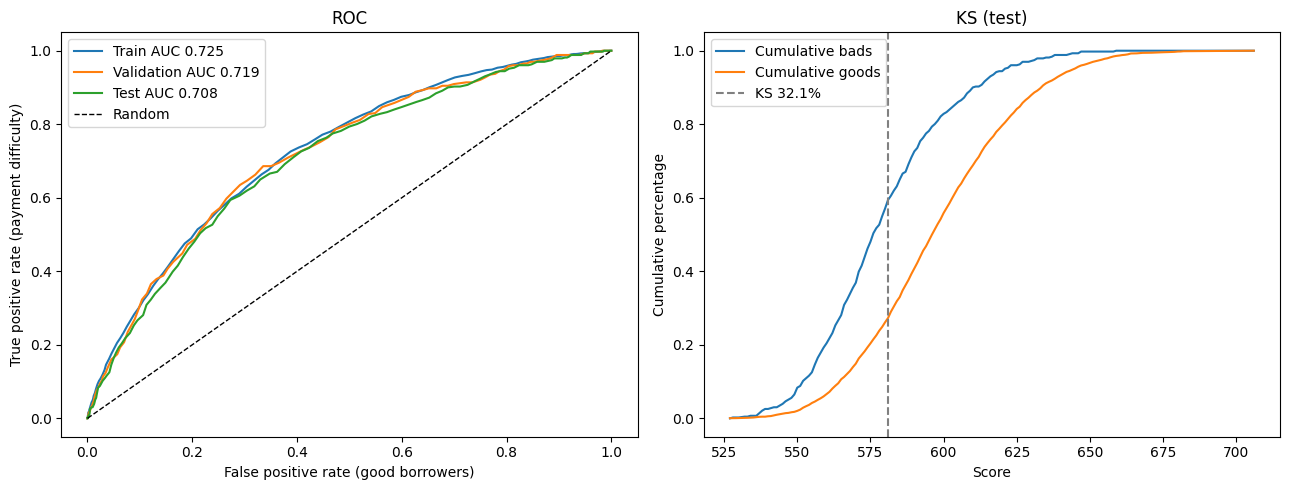

Test KS 32.12% at score 581


In [41]:
# UPDATED — final ROC and KS reporting (no further model decisions based on test).
fpr_tr, tpr_tr, _ = metrics.roc_curve(y_train, -train_score['score'].values)
fpr_va, tpr_va, _ = metrics.roc_curve(y_valid, -valid_score['score'].values)
fpr_te, tpr_te, _ = metrics.roc_curve(y_test, -test_score['score'].values)
ks_df = pd.DataFrame({'y': y_test.values, 'score': test_score['score'].values}).sort_values('score')
ks_df = ks_df.groupby('score')['y'].agg(bads='sum', n='size').cumsum()
ks_df['cum_bads'] = ks_df['bads'] / ks_df['bads'].iloc[-1]
ks_df['cum_goods'] = (ks_df['n'] - ks_df['bads']) / (ks_df['n'] - ks_df['bads']).iloc[-1]
ks_df['gap'] = ks_df['cum_bads'] - ks_df['cum_goods']
ks_score = ks_df['gap'].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr_tr, tpr_tr, label=f"Train AUC {perf.loc['train', 'AUC']:.3f}")
axes[0].plot(fpr_va, tpr_va, label=f"Validation AUC {perf.loc['validation', 'AUC']:.3f}")
axes[0].plot(fpr_te, tpr_te, label=f"Test AUC {perf.loc['test', 'AUC']:.3f}")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
axes[0].set_xlabel('False positive rate (good borrowers)')
axes[0].set_ylabel('True positive rate (payment difficulty)')
axes[0].set_title('ROC'); axes[0].legend()
axes[1].plot(ks_df.index, ks_df['cum_bads'], label='Cumulative bads')
axes[1].plot(ks_df.index, ks_df['cum_goods'], label='Cumulative goods')
axes[1].axvline(ks_score, ls='--', c='grey', label=f"KS {ks_df['gap'].max():.1%}")
axes[1].set_xlabel('Score'); axes[1].set_ylabel('Cumulative percentage')
axes[1].set_title('KS (test)'); axes[1].legend()
plt.tight_layout(); plt.savefig('g7_roc_ks_curves.png', dpi=150); plt.show()
print(f"Test KS {ks_df['gap'].max():.2%} at score {ks_score:.0f}")

**Score distribution** (Week 11 lab)

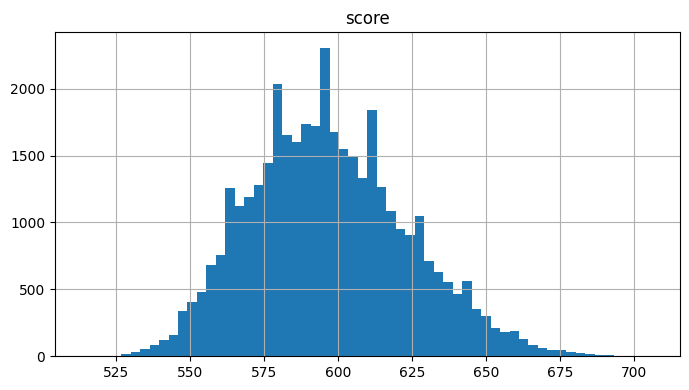

In [42]:
combined_score = pd.concat([train_score, valid_score, test_score], ignore_index=True)
combined_score.hist(figsize=(7, 4), bins=60)
plt.tight_layout()
plt.savefig('g7_score_distribution.png', dpi=150)
plt.show()

**Classification performance at a cutoff (Week 11 lab):** Applicants with scores below the cutoff are **predicted higher-risk / proposed for decline**. The confusion matrix compares these hypothetical decisions with historical `TARGET` outcomes; it does not identify which applicants the original lender rejected.

In [43]:
def show_performance(title, y_actual, predicted_list):
    cm = metrics.confusion_matrix(y_actual, predicted_list, labels=[0, 1])
    tp, fn, fp, tn = cm.ravel()
    labelled = pd.DataFrame(
        [[f'{tp:,}  (TP)', f'{fn:,}  (FN)'],
         [f'{fp:,}  (FP)', f'{tn:,}  (TN)']],
        index=['Actual: Good payer (0)', 'Actual: Payment difficulty (1)'],
        columns=['Predicted: Good payer (0)', 'Predicted: Payment difficulty (1)'])
    print(f'*** {title} ***')
    print(labelled.to_string())
    print(metrics.classification_report(y_actual, predicted_list, labels=[0, 1],
          target_names=['Good payer (0)', 'Payment difficulty (1)']))

def pcc_at(cutoff):
    show_performance(f'Train at {cutoff}', y_train,
                     (train_score['score'] < cutoff).astype(int).tolist())
    show_performance(f'Validation at {cutoff}', y_valid,
                     (valid_score['score'] < cutoff).astype(int).tolist())
    show_performance(f'Test at {cutoff}', y_test,
                     (test_score['score'] < cutoff).astype(int).tolist())

## Part 7. Cutoff, interest rate and profitability
### 7.1 Score cutoff and expected payment difficulties (Week 11 lab)

At each cutoff, calculate the approval fraction and sum score-implied probabilities for approved applicants. Using the 600-point anchor and PDO 20, model-implied good-to-bad odds are `19 × 2 ** ((score − 600) / 20)` and implied `P(TARGET=1) = 1 / (1 + odds)`.

Variables named `expected_defaults` and `actual_defaults` in the code refer to **expected and historically observed payment-difficulty cases**, not verified realised credit losses. The final cutoff is selected on validation using an illustrative profit formula.

In [44]:
def cutoff_table(score, y, cutoffs):
    rows = []
    for cutoff in cutoffs:
        approved = score['score'] >= cutoff
        odds = 19 * 2 ** ((score.loc[approved, 'score'] - 600) / 20)
        rows.append(dict(cutoff=cutoff, approved=int(approved.sum()),
                         approval_rate=approved.mean(),
                         expected_defaults=float((1 / (1 + odds)).sum()),
                         actual_defaults=int(y[approved].sum()),
                         bad_rate_approved=y[approved].mean()))
    return pd.DataFrame(rows)

lowest = int(min(train_score.score.min(), valid_score.score.min())) // 5 * 5
highest = int(max(train_score.score.quantile(.97), valid_score.score.quantile(.97)))
cutoffs = list(range(lowest, highest + 6, 5))
cutoff_train = cutoff_table(train_score, y_train, cutoffs)
cutoff_valid = cutoff_table(valid_score, y_valid, cutoffs)
print('Validation cutoff grid (outcome-based cutoff decisions must use this, not test):')
display(cutoff_valid[cutoff_valid.cutoff >= 540].round(4))

Validation cutoff grid (outcome-based cutoff decisions must use this, not test):


,cutoff,approved,approval_rate,expected_defaults,actual_defaults,bad_rate_approved
6,540,5718,0.9963,425.2900,423,0.0740
7,545,5676,0.9890,413.5226,415,0.0731
8,550,5612,0.9779,397.7709,397,0.0707
9,555,5503,0.9589,374.1309,377,0.0685
10,560,5325,0.9279,340.4162,347,0.0652
11,565,5101,0.8888,303.6006,304,0.0596
12,570,4803,0.8369,261.5087,263,0.0548
13,575,4526,0.7886,227.7000,227,0.0502
14,580,4152,0.7235,188.5336,184,0.0443
15,585,3753,0.6539,152.8594,145,0.0386



### 7.2 Hypothetical profitability and interest-rate scenarios

The profitability analysis evaluates the financial implications of different credit-score cutoffs under a simplified lending scenario.

Its purpose is to demonstrate how credit-risk screening may affect lending income and assumed credit losses. The outputs are **illustrative scenario results, not verified market figures, realised profits or a forecast of bank earnings**.

#### Financial assumptions

| Parameter | Assumed value | Interpretation |
|---|---|---|
| Product APR | 15% annually | Illustrative uniform annual lending rate applied across applicants. Interest is modelled through amortising monthly repayments, **not a flat-interest calculation**. |
| Cost of funds | 5% annually | Assumed annual funding rate used to estimate a simplified funding-interest amount. |
| Loss given default (LGD) | 70% of loan principal | Assumed loss severity for cases treated as losses in the scenario; not estimated from observed recoveries. |
| Loan principal | Applicant's `AMT_CREDIT` | Uses recorded loan amounts in unspecified dataset monetary units, not verified SGD. |
| Loan duration | 24 months | Hypothetical common repayment term, because actual contractual tenure is not confirmed. Sensitivity analyses consider 12, 24 and 36 months. |
| `TARGET = 0` | Treated as a good-outcome loan | Assigned simulated net-interest contribution. This does not independently verify full contractual repayment. |
| `TARGET = 1` | Treated as a loss event | Assigned an assumed loss of 70% of loan principal. This simplifies payment difficulty into a credit-loss scenario. |

#### Interest calculation

The notebook assumes an amortising loan with fixed monthly repayments.

For principal `P`, annual lending rate `a`, and assumed duration `n` months:

- Monthly rate: `r = a / 12`
- Monthly repayment: `P × r / [1 − (1 + r)^(-n)]`
- Total interest: `(Monthly repayment × n) − P`

The same repayment-based interest calculation is performed using the assumed 5% funding rate.

For a historically good-outcome loan:

`Net interest contribution = Total interest at 15% − Total interest at 5%`

This is a simplified approximation of lending income net of funding cost. It does not represent the bank's complete interest accounting or realised operating profit.

#### Treatment of payment difficulties

For cases with `TARGET = 1`, the scenario assumes:

`Credit loss = LGD × Loan principal`

With LGD of 70%, a loan principal of 200,000 dataset units would be assigned a loss of 140,000 units.

This treatment is deliberately simplified.

The historical target identifies recorded payment difficulties, **not necessarily permanent default or a realised 70% loss**.

The calculation does not separately model default timing, partial repayments, recoveries, collection costs or other possible cash flows.

Therefore, the simulated profit should not be interpreted as a verified expected-profit estimate.

#### Cutoff selection and evaluation

For each candidate cutoff, the notebook:

1. Identifies applicants whose credit scores meet the proposed approval threshold.
2. Calculates the simulated net-interest contribution for approved `TARGET = 0` cases.
3. Subtracts the assumed credit losses for approved `TARGET = 1` cases.
4. Aggregates these amounts to obtain the scenario profit.
5. Selects the cutoff that maximises scenario profitability on the **validation set**.

Under the baseline assumptions, the validation-selected cutoff is **565**.

The selected cutoff is subsequently evaluated on the test set without using test profitability to revise the lending policy.

A different cutoff may happen to produce higher profit in the test sample because the validation and test populations differ. Changing the cutoff based on those test results would weaken the independence of the evaluation.

#### Sensitivity and alternative pricing scenarios

Additional analyses examine how the results change when assumptions such as loan duration or LGD are modified.

The notebook also calculates illustrative break-even APRs for validation-defined score bands and evaluates an alternative tiered-pricing policy.

These calculations demonstrate how profitability may respond to different financial assumptions.

They do **not** establish actual market-appropriate lending rates, legal pricing limits, customer uptake, or demand responses to changes in interest rates.

**Interpretation:** The profitability analysis is a scenario-based decision-support exercise. Before real-world deployment, the lending institution would need actual loan terms, verified funding costs, observed credit losses, recovery information and customer response data.


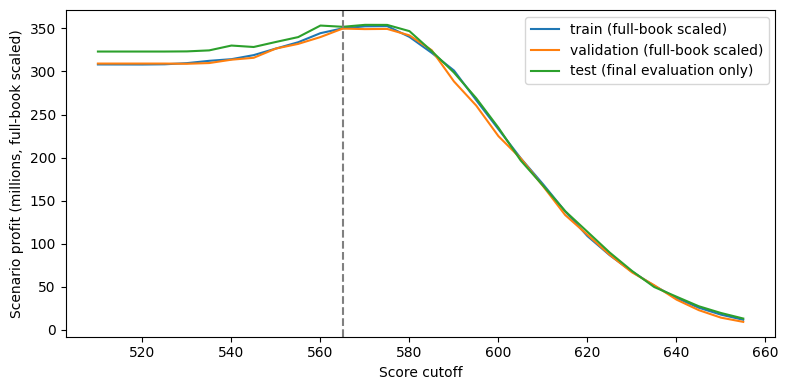

Validation-selected profit-maximising cutoff: 565


,cutoff,approved,approval_rate,defaults,bad_rate,revenue_m,losses_m,profit_m
6,540,5705,0.9939,420,0.0736,100.9099,51.3896,49.5203
8,550,5618,0.9787,403,0.0717,99.4641,49.3172,50.1470
10,560,5340,0.9303,348,0.0652,94.7925,41.7898,53.0027
11,565,5118,0.8916,316,0.0617,90.6917,37.9057,52.7860
12,570,4847,0.8444,278,0.0574,85.9778,32.8528,53.1251
14,580,4183,0.7287,194,0.0464,74.1827,22.1544,52.0282
16,590,3348,0.5833,125,0.0373,58.6991,13.8819,44.8172
18,600,2507,0.4368,77,0.0307,43.3226,8.1178,35.2048
20,610,1762,0.3070,47,0.0267,29.8992,4.7690,25.1303
22,620,1152,0.2007,24,0.0208,19.2411,2.1697,17.0714


,cutoff,approved,approval_rate,defaults,bad_rate,revenue_m,losses_m,profit_m
policy,,,,,,,,
approve everyone,510,5740,1.0000,431,0.0751,101.4369,52.9615,48.4754
cutoff 565,565,5118,0.8916,316,0.0617,90.6917,37.9057,52.7860


In [45]:
# UPDATED — defensible hypothetical term, validation-based cutoff, final test only for reporting.
APR, COST_OF_FUNDS, LGD = 0.15, 0.05, 0.70
ASSUMED_TERM_MONTHS = 24  # POLICY SCENARIO, not observed from this dataset

def total_interest(principal, months, apr):
    p = np.asarray(principal, dtype=float)
    m = np.asarray(months, dtype=float)
    if apr == 0:
        return np.zeros_like(p, dtype=float)
    r = apr / 12
    payment = p * r / (1 - (1 + r) ** (-m))
    return payment * m - p

def profit_frame(data, score, months=ASSUMED_TERM_MONTHS, apr=APR,
                 funding_cost=COST_OF_FUNDS, lgd=LGD):
    info = loan_info.loc[data.index]
    f = pd.DataFrame({'score': score['score'].values,
                      'TARGET': data['TARGET'].values,
                      'loan': info['AMT_CREDIT'].values,
                      'term': float(months)}, index=data.index)
    ni = total_interest(f.loan, f.term, apr) - total_interest(f.loan, f.term, funding_cost)
    f['profit'] = np.where(f.TARGET == 0, ni, -lgd * f.loan)
    return f

def profit_curve(f, cutoffs):
    rows = []
    for cutoff in cutoffs:
        a = f[f.score >= cutoff]
        goods, bads = a[a.TARGET == 0], a[a.TARGET == 1]
        rows.append(dict(cutoff=cutoff, approved=len(a),
                         approval_rate=len(a) / len(f), defaults=len(bads),
                         bad_rate=len(bads) / max(len(a), 1),
                         revenue_m=goods.profit.sum() / 1e6,
                         losses_m=-bads.profit.sum() / 1e6,
                         profit_m=a.profit.sum() / 1e6))
    return pd.DataFrame(rows)

pf_train = profit_frame(train, train_score)
pf_valid = profit_frame(valid, valid_score)
curve_train = profit_curve(pf_train, cutoffs)
curve_valid = profit_curve(pf_valid, cutoffs)
best_cutoff = int(curve_valid.loc[curve_valid.profit_m.idxmax(), 'cutoff'])

# Test is used ONCE after selection for independent reporting.
pf_test = profit_frame(test, test_score)
curve_test = profit_curve(pf_test, cutoffs)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve_train.cutoff, curve_train.profit_m * len(df) / len(train), label='train (full-book scaled)')
ax.plot(curve_valid.cutoff, curve_valid.profit_m * len(df) / len(valid), label='validation (full-book scaled)')
ax.plot(curve_test.cutoff, curve_test.profit_m * len(df) / len(test), label='test (final evaluation only)')
ax.axvline(best_cutoff, ls='--', c='grey')
ax.set_xlabel('Score cutoff'); ax.set_ylabel('Scenario profit (millions, full-book scaled)')
ax.legend(); plt.tight_layout(); plt.savefig('g7_profit_curve.png', dpi=150); plt.show()

print('Validation-selected profit-maximising cutoff:', best_cutoff)
profit_table = curve_test[((curve_test.cutoff % 10 == 0) & (curve_test.cutoff >= 540)) |
                          (curve_test.cutoff == best_cutoff)]
display(profit_table.round(4))
summary_cut = pd.concat([curve_test.iloc[[0]].assign(policy='approve everyone'),
                         curve_test[curve_test.cutoff == best_cutoff].assign(
                             policy=f'cutoff {best_cutoff}')])
display(summary_cut.set_index('policy').round(4))

In [46]:
# NEW — sensitivity of the recommended cutoff to assumed tenor and loss severity.
# Assess on VALIDATION only; test is not used for tuning.
sensitivity = []
for tenor in [12, 24, 36]:
    for severity in [0.50, 0.70, 0.90]:
        scenario = profit_frame(valid, valid_score, months=tenor, lgd=severity)
        c = profit_curve(scenario, cutoffs)
        optimum = c.loc[c.profit_m.idxmax()]
        chosen = c.loc[c.cutoff == best_cutoff].iloc[0]
        sensitivity.append({'term_months': tenor, 'LGD': severity,
                            'optimal_cutoff_on_validation': int(optimum.cutoff),
                            'profit_at_original_cutoff_m': chosen.profit_m,
                            'maximum_profit_m': optimum.profit_m})
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity.round(3))
sensitivity.to_csv('g7_profit_sensitivity.csv', index=False)


,term_months,LGD,optimal_cutoff_on_validation,profit_at_original_cutoff_m,maximum_profit_m
0,12,0.5,580,18.583,21.231
1,12,0.7,585,7.921,15.999
2,12,0.9,595,-2.742,11.190
3,24,0.5,555,63.131,63.193
4,24,0.7,565,52.469,52.469
5,24,0.9,580,41.806,45.026
6,36,0.5,540,110.335,114.946
7,36,0.7,550,99.673,100.788
8,36,0.9,565,89.010,89.010


In [47]:
# UPDATED — derive pricing from validation, never actual test outcomes.
def breakeven_apr(g):
    if len(g) == 0:
        return pd.Series({'applicants': 0, 'bad_rate': np.nan, 'breakeven_APR': np.nan})
    def band_profit(apr):
        ni = total_interest(g.loan, g.term, apr) - total_interest(g.loan, g.term, COST_OF_FUNDS)
        return ((1 - g.TARGET) * ni - g.TARGET * LGD * g.loan).sum()
    lo, hi = 0.0, 2.0
    if band_profit(hi) < 0:
        return pd.Series({'applicants': len(g), 'bad_rate': g.TARGET.mean(),
                          'breakeven_APR': np.nan})
    for _ in range(60):
        mid = (lo + hi) / 2
        if band_profit(mid) < 0:
            lo = mid
        else:
            hi = mid
    return pd.Series({'applicants': len(g), 'bad_rate': g.TARGET.mean(),
                      'breakeven_APR': hi})

edges = [-np.inf, best_cutoff, best_cutoff + 20, best_cutoff + 40,
         best_cutoff + 60, np.inf]
pf_valid['band'] = pd.cut(pf_valid.score, edges, right=False)
pricing = pd.DataFrame([
    breakeven_apr(pf_valid.loc[pf_valid.band == band])
    for band in pf_valid['band'].cat.categories
], index=pf_valid['band'].cat.categories)
pricing.index.name = 'band'
print('Pricing estimated from VALIDATION outcomes only; treat as a scenario, not a deployed APR.')
display(pricing.round(4))

Pricing estimated from VALIDATION outcomes only; treat as a scenario, not a deployed APR.


,applicants,bad_rate,breakeven_APR
band,,,
"[-inf, 565.0)",638.0,0.1975,0.2042
"[565.0, 585.0)",1348.0,0.1180,0.1346
"[585.0, 605.0)",1646.0,0.0553,0.0880
"[605.0, 625.0)",1202.0,0.0324,0.0713
"[625.0, inf)",905.0,0.0166,0.0612


**Illustrative score-band pricing and origination policy.** The **flat 15% APR** is the baseline scenario used for the primary cutoff/profit comparison. Separately, validation-based break-even rates plus a 3-percentage-point assumed margin are rounded up to the nearest 0.5% to form an **alternative tiered-pricing scenario**. Score bands also define assumed document/clinic verification requirements. The model does not estimate demand changes, legal pricing constraints or customer uptake at different rates.

In [48]:
MARGIN = 0.03  # illustrative operating-cost / target-margin assumption

tiers = pricing.reset_index(drop=True)
tiers.insert(0, 'score_band', [f'below {best_cutoff}', f'{best_cutoff}-{best_cutoff + 19}',
                              f'{best_cutoff + 20}-{best_cutoff + 39}',
                              f'{best_cutoff + 40}-{best_cutoff + 59}',
                              f'{best_cutoff + 60} and above'])
tiers.insert(0, 'tier', ['Decline', 'Tier 4 (Higher risk)', 'Tier 3 (Standard)',
                         'Tier 2 (Near prime)', 'Tier 1 (Prime)'])
tiers['indicative_APR'] = np.ceil((tiers['breakeven_APR'] + MARGIN) * 200) / 200
tiers.loc[0, 'indicative_APR'] = np.nan
tiers['origination_policy'] = [
    'Decline, or refer for a co-signer or security',
    'Approve after full income and verified clinic-plan review',
    'Approve after income and clinic-plan checks',
    'Approve with standard documents and verified clinic quote',
    'Approve with standard documents; verify clinic before direct payment',
]
assert len(tiers) == 5
if (tiers.loc[1:4, 'applicants'] < 100).any():
    print('CAUTION: some validation pricing bands are small; rates may be unstable.')
print('Validation-derived APR tiers (not necessarily market-legal prices):')
display(tiers.iloc[::-1].reset_index(drop=True).round(4))
tiers.to_csv('g7_pricing_scenario_validation.csv', index=False)

Validation-derived APR tiers (not necessarily market-legal prices):


,tier,score_band,applicants,bad_rate,breakeven_APR,indicative_APR,origination_policy
0,Tier 1 (Prime),625 and above,905.0,0.0166,0.0612,0.095,Approve with standard documents; verify clinic...
1,Tier 2 (Near prime),605-624,1202.0,0.0324,0.0713,0.105,Approve with standard documents and verified c...
2,Tier 3 (Standard),585-604,1646.0,0.0553,0.0880,0.120,Approve after income and clinic-plan checks
3,Tier 4 (Higher risk),565-584,1348.0,0.1180,0.1346,0.165,Approve after full income and verified clinic-...
4,Decline,below 565,638.0,0.1975,0.2042,NaN,"Decline, or refer for a co-signer or security"


In [49]:
# Profit at the cutoff if each tier pays its indicative APR (test set, reporting only)
apr_of = tiers.set_index('tier')['indicative_APR']
band_apr = [apr_of['Tier 4 (Higher risk)'], apr_of['Tier 3 (Standard)'],
            apr_of['Tier 2 (Near prime)'], apr_of['Tier 1 (Prime)']]
approved = pf_test[pf_test.score >= best_cutoff].copy()
approved['apr'] = pd.cut(approved.score, [best_cutoff, best_cutoff + 20, best_cutoff + 40, best_cutoff + 60, np.inf],
                         right=False, labels=band_apr, ordered=False).astype(float)
r = approved['apr'] / 12
interest = approved.loan * r / (1 - (1 + r) ** -approved.term) * approved.term - approved.loan
net_interest = interest - total_interest(approved.loan, approved.term, COST_OF_FUNDS)
approved['profit_tiered'] = np.where(approved.TARGET == 0, net_interest, -LGD * approved.loan)
print(f"Cutoff {best_cutoff}: flat {APR:.0%} {approved.profit.sum()/1e6:,.1f}m | "
      f"tiered {approved.profit_tiered.sum()/1e6:,.1f}m | approve all {pf_test.profit.sum()/1e6:,.1f}m")

Cutoff 565: flat 15% 52.8m | tiered 29.2m | approve all 48.5m


**PCC measures at the chosen cutoff**

In [50]:
pcc_at(best_cutoff)

*** Train at 565 ***
                               Predicted: Good payer (0) Predicted: Payment difficulty (1)
Actual: Good payer (0)                      22,569  (TP)                       2,205  (FN)
Actual: Payment difficulty (1)               1,442  (FP)                         568  (TN)
                        precision    recall  f1-score   support

        Good payer (0)       0.94      0.91      0.93     24774
Payment difficulty (1)       0.20      0.28      0.24      2010

              accuracy                           0.86     26784
             macro avg       0.57      0.60      0.58     26784
          weighted avg       0.88      0.86      0.87     26784

*** Validation at 565 ***
                               Predicted: Good payer (0) Predicted: Payment difficulty (1)
Actual: Good payer (0)                       4,797  (TP)                         512  (FN)
Actual: Payment difficulty (1)                 304  (FP)                         126  (TN)
                    

                        precision    recall  f1-score   support

        Good payer (0)       0.94      0.90      0.92      5309
Payment difficulty (1)       0.18      0.27      0.22       431

              accuracy                           0.86      5740
             macro avg       0.56      0.59      0.57      5740
          weighted avg       0.88      0.86      0.87      5740



**Summary classification measures at the selected cutoff (test set).** For these measures the *positive decision* is approval, and the reference label is **`TARGET = 0` (no recorded payment difficulties)**.

* **Accuracy:** Fraction whose historical `TARGET` agrees with the simulated approve/decline decision.
* **Sensitivity / recall for goods:** Share of `TARGET=0` applicants who would be approved.
* **Specificity for payment-difficulty cases:** Share of `TARGET=1` applicants who would be declined.
* **Precision for approvals:** Share of approved applicants whose historical `TARGET=0`.
* **F1 for goods:** Harmonic mean of approval precision and recall.

These are retrospective outcome comparisons; they do not mean every `TARGET=0` borrower necessarily fully repaid, or that the original lender actually approved/declined borrowers at this score cutoff.

In [51]:
pred_good = (test_score['score'].values >= best_cutoff)
actual_good = (y_test.values == 0)
TP = int((pred_good & actual_good).sum());   FN = int((~pred_good & actual_good).sum())
FP = int((pred_good & ~actual_good).sum());  TN = int((~pred_good & ~actual_good).sum())
accuracy = (TP + TN) / len(actual_good)
precision, recall = TP / (TP + FP), TP / (TP + FN)
cutoff_measures = pd.Series({
    'Accuracy': accuracy,
    'Error rate': 1 - accuracy,
    'Sensitivity / recall (TARGET=0 applicants approved)': recall,
    'Specificity (payment-difficulty cases declined)': TN / (TN + FP),
    'Precision (approved applicants with TARGET=0)': precision,
    'F1 score (good payers)': 2 * precision * recall / (precision + recall)})
cutoff_measures.map('{:.2%}'.format)

Accuracy                                               85.66%
Error rate                                             14.34%
Sensitivity / recall (TARGET=0 applicants approved)    90.45%
Specificity (payment-difficulty cases declined)        26.68%
Precision (approved applicants with TARGET=0)          93.83%
F1 score (good payers)                                 92.11%
dtype: object

## Part 8. Scorecard walkthrough (Week 11 Ex Q1 style)
Three test applicants at the 10th, 50th and 90th percentile of score. Their points are looked up bin by bin with
`sc.scorecard_ply(..., only_total_score=False)`, added up, and compared with the cutoff.

In [52]:
# UPDATED — verify each applicant's point total matches the scoring pipeline.
examples = []
for q in (0.10, 0.50, 0.90):
    examples.append((test_score['score'] - test_score['score'].quantile(q)).abs().idxmin())
walkthrough = []
for i in examples:
    appl = test.loc[[i], [c[:-4] for c in selected]]
    pts = sc.scorecard_ply(appl, card, only_total_score=False).transpose()
    total = int(pts.loc['score'].iloc[0])
    assert total == int(test_score.loc[i, 'score']), f'Point total mismatch for index {i}'
    pts = pts.drop(index='score'); pts.index = pts.index.str.replace('_points', '', regex=False)
    summary = pd.concat([appl.transpose(), pts], axis=1)
    summary.columns = ['App Value', 'Points']
    sid = int(df.loc[i, 'SK_ID_CURR'])
    decision = 'APPROVE' if total >= best_cutoff else 'DECLINE'
    print(f'\nApplicant {sid}: total {total} -> {decision} (cutoff {best_cutoff}); actual TARGET={test.loc[i, "TARGET"]}')
    print(summary.to_string())
    walkthrough.append({'SK_ID_CURR': sid, 'score': total, 'decision': decision,
                        'observed_payment_difficulty': int(test.loc[i, 'TARGET'])})
walkthrough = pd.DataFrame(walkthrough)
walkthrough.to_csv('g7_applicant_walkthrough_test.csv', index=False)
print('WALKTHROUGH AUDIT: all 3 score totals match the final test score output')


Applicant 190847: total 563 -> DECLINE (cutoff 565); actual TARGET=0
                                         App Value  Points
TERM_MONTHS                              15.360983    40.0
YEARS_EMPLOYED                            5.697467    44.0
BUR_SHARE_ACTIVE                               NaN    34.0
EXT_SOURCE_1                                   NaN    41.0
NAME_EDUCATION_TYPE  Secondary / secondary special    40.0
BUR_N_OPENED_12M                               0.0    44.0
BUR_MAX_AMT_OVERDUE                            NaN    40.0
YEARS_ID_PUBLISH                          5.848049    39.0
OCCUPATION_TYPE                 Low-skill Laborers    39.0
CREDIT_TO_GOODS                                1.0    42.0
LIVINGAREA_MEDI                                NaN    40.0
BUR_UTILISATION                                NaN    42.0
AMT_CREDIT                                225000.0    40.0
NAME_FAMILY_STATUS            Single / not married    38.0



Applicant 388013: total 595 -> APPROVE (cutoff 565); actual TARGET=0
                                         App Value  Points
TERM_MONTHS                              18.243655    40.0
YEARS_EMPLOYED                                 NaN    49.0
BUR_SHARE_ACTIVE                               NaN    34.0
EXT_SOURCE_1                              0.679527    53.0
NAME_EDUCATION_TYPE  Secondary / secondary special    40.0
BUR_N_OPENED_12M                               0.0    44.0
BUR_MAX_AMT_OVERDUE                            NaN    40.0
YEARS_ID_PUBLISH                           10.9295    42.0
OCCUPATION_TYPE                                NaN    45.0
CREDIT_TO_GOODS                              1.198    40.0
LIVINGAREA_MEDI                             0.0641    48.0
BUR_UTILISATION                                NaN    42.0
AMT_CREDIT                                226422.0    40.0
NAME_FAMILY_STATUS            Single / not married    38.0

Applicant 319977: total 633 -> APPROVE (cuto

In [53]:
# NEW — real-world prediction contract: future rows only need the final selected predictor fields.
final_raw_features = [name[:-4] for name in selected]
print('Features required for scoring a new applicant:', final_raw_features)
minimal_test = test[final_raw_features].copy()
reduced_scores = sc.scorecard_ply(minimal_test, card)
reduced_scores.index = minimal_test.index
assert np.array_equal(reduced_scores['score'].to_numpy(), test_score['score'].to_numpy())
pd.DataFrame({'required_raw_feature': final_raw_features}).to_csv('g7_deployment_features.csv', index=False)
print('DEPLOYMENT AUDIT: removing all other predictor columns does not change the score.')

Features required for scoring a new applicant: ['TERM_MONTHS', 'YEARS_EMPLOYED', 'BUR_SHARE_ACTIVE', 'EXT_SOURCE_1', 'NAME_EDUCATION_TYPE', 'BUR_N_OPENED_12M', 'BUR_MAX_AMT_OVERDUE', 'YEARS_ID_PUBLISH', 'OCCUPATION_TYPE', 'CREDIT_TO_GOODS', 'LIVINGAREA_MEDI', 'BUR_UTILISATION', 'AMT_CREDIT', 'NAME_FAMILY_STATUS']


DEPLOYMENT AUDIT: removing all other predictor columns does not change the score.


## Summary

In [54]:
acc = curve_test.loc[curve_test.cutoff == best_cutoff].iloc[0]
allp = curve_test.iloc[0]
print('=' * 78)
print('SCORECARD SUMMARY — G1-7 Medical Procedure Loan (reviewed pipeline)')
print('=' * 78)
print(f'segment {len(df):,} | train {len(train):,} | valid {len(valid):,} | test {len(test):,}')
print(f'observed segment payment-difficulty rate: {df.TARGET.mean():.2%}')
print(f'screening: {len(iv_fine)} candidates -> {len(screened)} fine IV >= .02 -> '
      f'{len(coarse_kept)} coarse IV >= .02 -> {len(candidates)} WOE candidates -> '
      f'{len(selected)} model predictors')
print(f'final test: AUC {perf.loc["test", "AUC"]:.4f} | Gini {perf.loc["test", "Gini"]:.4f} | '
      f'KS {perf.loc["test", "KS"]:.4f}')
print('score scale: 600 points = 1:19 bad:good odds; PDO 20')
print(f'cutoff {best_cutoff} (VALIDATION-CHOSEN): test approval {acc.approval_rate:.1%} | '
      f'approved bad rate {acc.bad_rate:.2%} vs {allp.bad_rate:.2%} if all approved')
print(f'test scenario profit {acc.profit_m:.1f}m vs {allp.profit_m:.1f}m (illustrative only)')
print(f'Assumed term {ASSUMED_TERM_MONTHS} months; APR {APR:.0%}; COF {COST_OF_FUNDS:.0%}; LGD {LGD:.0%}')
assert np.isfinite(perf.loc['test', 'AUC'])
assert acc.approved == int((test_score.score >= best_cutoff).sum())
print('FINAL AUDIT: scorecard + cutoff + test accounting consistent')

SCORECARD SUMMARY — G1-7 Medical Procedure Loan (reviewed pipeline)
segment 38,263 | train 26,784 | valid 5,739 | test 5,740
observed segment payment-difficulty rate: 7.50%
screening: 102 candidates -> 49 fine IV >= .02 -> 41 coarse IV >= .02 -> 32 WOE candidates -> 14 model predictors
final test: AUC 0.7080 | Gini 0.4159 | KS 0.3212
score scale: 600 points = 1:19 bad:good odds; PDO 20
cutoff 565 (VALIDATION-CHOSEN): test approval 89.2% | approved bad rate 6.17% vs 7.51% if all approved
test scenario profit 52.8m vs 48.5m (illustrative only)
Assumed term 24 months; APR 15%; COF 5%; LGD 70%
FINAL AUDIT: scorecard + cutoff + test accounting consistent



## Part 9. Limitations and Recommendations

### 9.1 Overall model assessment

The final scorecard uses **14 selected variables** and demonstrates moderate predictive discrimination on the historical test dataset.

Key results include:

| Metric | Final test result |
|---|---:|
| Test applicants | 5,740 |
| AUC | 0.7080 |
| Gini | 0.4159 |
| KS | 32.12% |
| Validation-selected cutoff | 565 |
| Test approval rate | 89.16% |
| Historical bad rate among approved applicants | 6.17% |

The model provides an interpretable credit-risk screening framework, with individual WoE bins contributing points to each applicant's total score.

However, these results should not be interpreted as proof that the scorecard is ready for real-world medical-loan deployment.

### 9.2 Limitation 1 — Medical-loan proxy and population representativeness

The original dataset does not explicitly identify medical-purpose loans.

The selected cash-loan segment is therefore an assumed proxy for a medical procedure financing product.

Although the model can demonstrate credit-scoring methods on this segment, the risk characteristics of actual medical-loan borrowers may differ.

Medical financing may involve different borrowing motivations, treatment costs, repayment structures and customer circumstances.

Furthermore, the dataset's monetary units are not confirmed to be SGD, so the numerical loan-amount thresholds cannot be interpreted as verified Singapore medical-procedure costs.

**Recommendation:** Validate the scorecard using actual medical-loan applications, verified product information and subsequent repayment outcomes before applying it to the intended customer population.

### 9.3 Limitation 2 — Classification errors and selection bias

The model has moderate discrimination rather than perfect predictive accuracy.

At the selected cutoff of 565:

- **5,118 of 5,740** test applicants would be approved.
- **507 of 5,309** historically good-outcome applicants would be declined (9.55%).
- **316 of 431** historical payment-difficulty cases would still be approved (73.32%).
- The observed payment-difficulty rate among approved applicants is **6.17%**, compared with **7.51%** for the complete test population.

These results demonstrate the trade-off between approving more customers and reducing credit risk.

Another limitation is potential historical selection bias.

Repayment outcomes are generally unavailable for applicants who were originally rejected and did not receive loans. Therefore, the available observed outcomes may not fully represent the risk of all future applicants.

The random train/validation/test split supports model development and evaluation within the available historical sample, but does not resolve this representativeness issue.

Earlier project iterations also examined the test sample. Although the final pipeline separates training, validation and testing appropriately, the current test results should not be presented as a completely untouched external evaluation of the entire development history.

**Recommendation:** Conduct external or out-of-time validation using additional representative data. Consider manual review for borderline scorecard decisions, supported by consistent and documented lending criteria.

### 9.4 Limitation 3 — Financial assumptions and estimated profitability

The scenario-based profitability analysis assumes:

- 15% annual lending APR.
- 5% annual cost of funds.
- 70% loss given default.
- A common 24-month loan duration.

These assumptions are not independently verified from the historical dataset.

In particular, `TARGET = 1` indicates recorded repayment difficulty rather than necessarily a realised default or permanent principal loss.

Treating every `TARGET = 1` case as a 70% principal loss is a simplified modelling assumption.

As a result, the reported profitability figures represent retrospective hypothetical scenarios rather than actual or guaranteed bank profits.

**Recommendation:** Reassess the proposed cutoff and pricing using actual contractual terms, funding costs, observed losses, recovery rates and operating expenses. Conduct further sensitivity analysis before adopting a lending policy.

### 9.5 Limitation 4 — Fairness and responsible lending

The final scorecard includes variables such as occupation, education, family status and housing-related characteristics.

Although these variables were retained because they contributed predictive information, statistical predictiveness does not automatically establish fairness.

Some variables may indirectly reflect socioeconomic or demographic differences and could contribute to unequal lending outcomes.

Gender was excluded as a direct predictor, but removing a sensitive variable alone does not guarantee that the resulting model is free from bias.

A formal subgroup fairness assessment was not conducted in the current modelling pipeline.

**Recommendation:** Evaluate approval rates, false rejection rates and predictive performance across relevant customer groups. Investigate potentially discriminatory proxy relationships and compare alternative feature sets where appropriate.

Any human-review process should also use consistent, documented criteria to minimise subjective or unequal treatment.

### 9.6 Recommendation for deployment

The proposed scorecard should be treated as a **proof-of-concept credit-risk screening tool**, not a production-ready automated lending system.

Before real-world implementation, a lending institution should:

1. **Validate the target population:** Use actual medical-loan application and repayment data.
2. **Verify affordability:** Supplement model scores with documented income, existing obligations and repayment-capacity checks.
3. **Reassess financial assumptions:** Replace hypothetical APR, funding cost, LGD and tenure assumptions with institution-specific evidence.
4. **Evaluate fairness:** Conduct subgroup analysis and assess whether selected predictors are appropriate for lending decisions.
5. **Establish review procedures:** Provide documented review processes for borderline cases and applications requiring additional verification.
6. **Monitor the model:** Track discrimination, probability calibration, score distributions, approval outcomes, missing-data rates, fairness and realised credit losses over time.

### 9.7 Conclusion

The project demonstrates a complete, interpretable credit-scorecard development process, including application and bureau data integration, IV/WoE screening, validation-based forward selection, logistic regression, score scaling and profitability-based cutoff selection.

The final 14-variable model achieves moderate historical risk discrimination and illustrates how a credit score can support consistent lending decisions.

Nevertheless, product-specific data limitations, classification errors, potential selection bias, fairness concerns and assumption-dependent profitability remain unresolved.

**The scorecard is therefore recommended as a foundation for further validation and responsible lending-policy development, rather than for immediate automated medical-loan approval.**
